# GeocarbPrecalibration.jl: a guided tour

*The GEOCARBSULFvolc long-term carbon-cycle model in Julia: what it is, how to set
it up and run it, and the evidence that it reproduces the original R/Fortran code.*

> This notebook is generated from `notebooks/tour.jl` with Literate.jl; edit that
> file, not the `.ipynb`, and regenerate with `julia --project=notebooks notebooks/build.jl`.

### How to read this notebook

| if you are | read |
|:--|:--|
| new to the package | *Setup* and *Part 1* |
| reviewing the software (for example for JOSS) | *Setup*, *Part 1* and *Part 2* |
| examining the port from R/Fortran to Julia | *Part 2*; section 2.1 says what "the same answer" means |

**Contents**

- **Setup**: installing, opening the notebook, checking this machine
- **Part 1, the package and the model**: 1.1 the science · 1.2 the package · 1.3 the
  model · 1.4 inputs · 1.5 a first run · 1.6 climate sensitivity · 1.7 failed steps ·
  1.8 options and supplemental experiments · 1.9 single-precision literals · 1.10
  windows and % outbound · 1.11 a small precalibration · 1.12 its results · 1.13
  going further
- **Part 2, verification against the original code**: 2.1 what "the same answer"
  means · 2.2 three levels of evidence · 2.3 the test suite · 2.4 level A · 2.5 level B
  · 2.6 level C · 2.7 verdict · 2.8 reproducibility record

## Setup

### Installing (once)

1. **Julia.** Install [juliaup](https://github.com/JuliaLang/juliaup), the official
   Julia installer, then Julia 1.12:
   - Windows: `winget install --name Julia --id 9NJNWW8PVKMN -e -s msstore`
   - macOS and Linux: `curl -fsSL https://install.julialang.org | sh`
   - then, in a new terminal: `juliaup add 1.12` and `juliaup default 1.12`
2. **The repository.** `git clone https://github.com/TrevorLax/GEOCARBSULF.git` and
   change into the new folder.
3. **The notebook environment.** From the repository folder run
   `julia notebooks/setup.jl`. It instantiates the package environment (used by the
   test cells), creates the separate notebook environment in `notebooks/` with the
   package, CairoMakie, IJulia and Literate, precompiles everything, installs a
   Jupyter kernel called *GeocarbPrecalibration* that starts Julia with all CPU
   threads, and writes `notebooks/GeocarbPrecalibration_tour.ipynb`. The first run
   takes roughly 5 to 15 minutes, mostly precompiling CairoMakie.
   - In VS Code, if the kernel does not appear at first run, you may need to run from the command palette "Developer: Reload Window," after which the list under Select Kernel > Select Another Kernel  > Jupyter Kernels... should include *GeocarbPrecalibration 1.12*.
4. **Opening the tour notebook.** Any Jupyter front end works:
   - JupyterLab, if you have it: `jupyter lab notebooks/GeocarbPrecalibration_tour.ipynb`;
   - VS Code with the Jupyter extension: open the `.ipynb` file;
   - without either: `julia --project=notebooks -e "using IJulia; jupyterlab(dir=pwd())"`
     (IJulia offers to install a private copy of Jupyter the first time).

   Choose the kernel **GeocarbPrecalibration** and run the cells from top to bottom
   (in JupyterLab: *Run → Run All Cells*).

**Optional, only for level C of Part 2** (a live run of the original code):

- **R** ≥ 4.1 (the comparison was last run with R 4.6.1), with the packages
  `lhs`, `CholWishart` and `abind` (`MASS` ships with R). In R:
  `install.packages(c("lhs", "CholWishart", "abind"))`.
- **A Fortran compiler** that R can use, to compile the original Fortran:
  - Windows: [Rtools](https://cran.r-project.org/bin/windows/Rtools/) matching your R version;
  - macOS: the gfortran build linked from [mac.r-project.org/tools](https://mac.r-project.org/tools/);
  - Linux: your distribution's `gfortran` package (for example `sudo apt install gfortran r-base`).

> ⚠️ **CairoMakie is slow the first time.** Loading CairoMakie and drawing the first
> figure can take **several minutes** in a fresh environment (Julia compiles the
> plotting code once, then caches it). Later figures, and later sessions, are fast.
> The first code cell below is the slow one; let it finish.

> ⚠️ **Level C needs R and gfortran.** Without R (with the packages above) and a
> Fortran compiler, or already compiled libraries in `legacy/fortran`, the notebook
> skips level C and says why. Levels A and B never need R.

In [1]:
using GeocarbPrecalibration
using CairoMakie  # loading a Makie backend also loads the package's plotting extension
include(joinpath(pkgdir(GeocarbPrecalibration), "notebooks", "tour_helpers.jl"))
set_tour_theme!()
julia_version_check()

> ✅ Julia 1.12.6.



The helpers loaded above (`notebooks/tour_helpers.jl`) only present results: they
run the test suite in subprocesses, load the repository's own comparison code, and
draw tables and figures. None of them contains model code.

### Settings

Edit and re-run this cell to change what the notebook does. `FAST` is the quick mode
used by the automated test of this notebook (`notebooks/test_notebook.jl`).

In [2]:
FAST = get(ENV, "GEOCARB_NOTEBOOK_FAST", "false") == "true"
TEST_GROUPS = FAST ? ["constraints", "regression"] : DEFAULT_GROUPS  # test groups run in Part 2
RUN_LEVEL_B = true    # replay stored R exports, if this machine has any
RUN_LEVEL_C = :auto   # :auto = run if R and a Fortran compiler are found; true or false to force
N_DRAWS = FAST ? 100 : 400  # random prior draws used in Part 1
println("quick mode: ", FAST, " · Julia threads: ", Threads.nthreads())

quick mode: false · Julia threads: 4


### This machine

What the notebook found. The last five rows decide whether levels B and C of Part 2
can run.

In [3]:
env = detect_environment()
environment_table(env)

,found,needed for
Julia,1.12.6,≥ 1.10 required; 1.12 recommended
Threads,4,
Operating system,Darwin aarch64,
GeocarbPrecalibration,0.1.0 (commit 9e1db80),
CairoMakie,0.15.17,
Rscript,✘ not found,level C
"R packages lhs, CholWishart, abind, MASS",✘,level C
Compiled legacy Fortran,✘ not found,level C (either this or a compiler)
Fortran compiler,✘ not found,level C
Stored R exports,✘ none in test/legacy_comparison/output,level B


## Part 1: the package and the model

### 1.1 The science in brief

Over millions of years, the amount of CO₂ in the atmosphere is set by a slow balance.
Volcanism and metamorphism release carbon from the solid Earth. Chemical weathering
of silicate rocks on land removes it, and the carbon ends up buried in carbonate
rocks and in organic matter in sediments. Weathering speeds up when the climate is
warmer and wetter, so this balance acts as a **thermostat**: if CO₂ rises, the planet
warms, weathering accelerates and draws CO₂ down again.

The **GEOCARB** family of models (Berner 2004, 2006, 2008; Royer et al. 2014) turns
this idea into a budget of carbon and sulfur reservoirs from 570 million years ago
(Ma) to the present, in 10-million-year steps. At each step the model solves for the
CO₂ level at which weathering balances the carbon that must be removed. It also
tracks atmospheric O₂ and isotope ratios.

One parameter, **ΔT2x**, is the warming per doubling of CO₂. Over these time scales
it includes slow feedbacks such as ice sheets and vegetation, so it measures
*Earth-system sensitivity*. Another, **GLAC**, scales it during glacial periods.

**Precalibration** (Wong et al. 2021, *Nature Communications* 12, 3173) asks which
combinations of the uncertain parameters give model histories consistent with the
geological record. It draws many parameter sets from their prior distributions, runs
the model for each, and keeps those whose CO₂ and temperature stay inside
observational *windows* (built from CO₂ proxies and a temperature reconstruction)
often enough. The kept samples constrain ΔT2x.

### 1.2 What this package is

`GeocarbPrecalibration.jl` is a Julia port of the R/Fortran code of Wong et al.
(2021) (`GEOCARB-precalibration`, by Tony Wong and Ying Cui). The original code is
kept, unmodified, in `legacy/` and is used as the test oracle in Part 2.

| layer | folder | what it does |
|:--|:--|:--|
| parameters | `src/parameters/` | named constants, forcings and model options |
| model | `src/model/` | `run_geocarb`, a line-by-line port of `run_geocarb.f90` |
| inputs | `src/io/` | readers for the prior table, forcing arrays, proxies, temperatures |
| priors and samplers | `src/priors/`, `src/sampling/` | truncated priors, Latin hypercube, inverse-Wishart forcing samples |
| constraints | `src/constraints/` | CO₂ and temperature windows, % outbound |
| precalibration | `src/precalibration/` | experiment files, acceptance rules, the chunked threaded engine |
| analysis and plots | `src/analysis/`, `ext/` | the paper's summaries; figures with Makie |

Compared with the original:

- **experiments are TOML files** (`experiments/`) instead of edited scripts;
- **model variants are options** (`ModelOptions`) instead of a second copy of the Fortran;
- **runs never crash** on bad parameter values: every time step gets a status;
- **ensembles are deterministic** whatever the number of threads, and can be checkpointed;
- **everything is tested**, including against the original code (Part 2).

### 1.3 The model

A sketch of the carbon budget the model keeps (sulfur, oxygen and strontium are
tracked alongside):

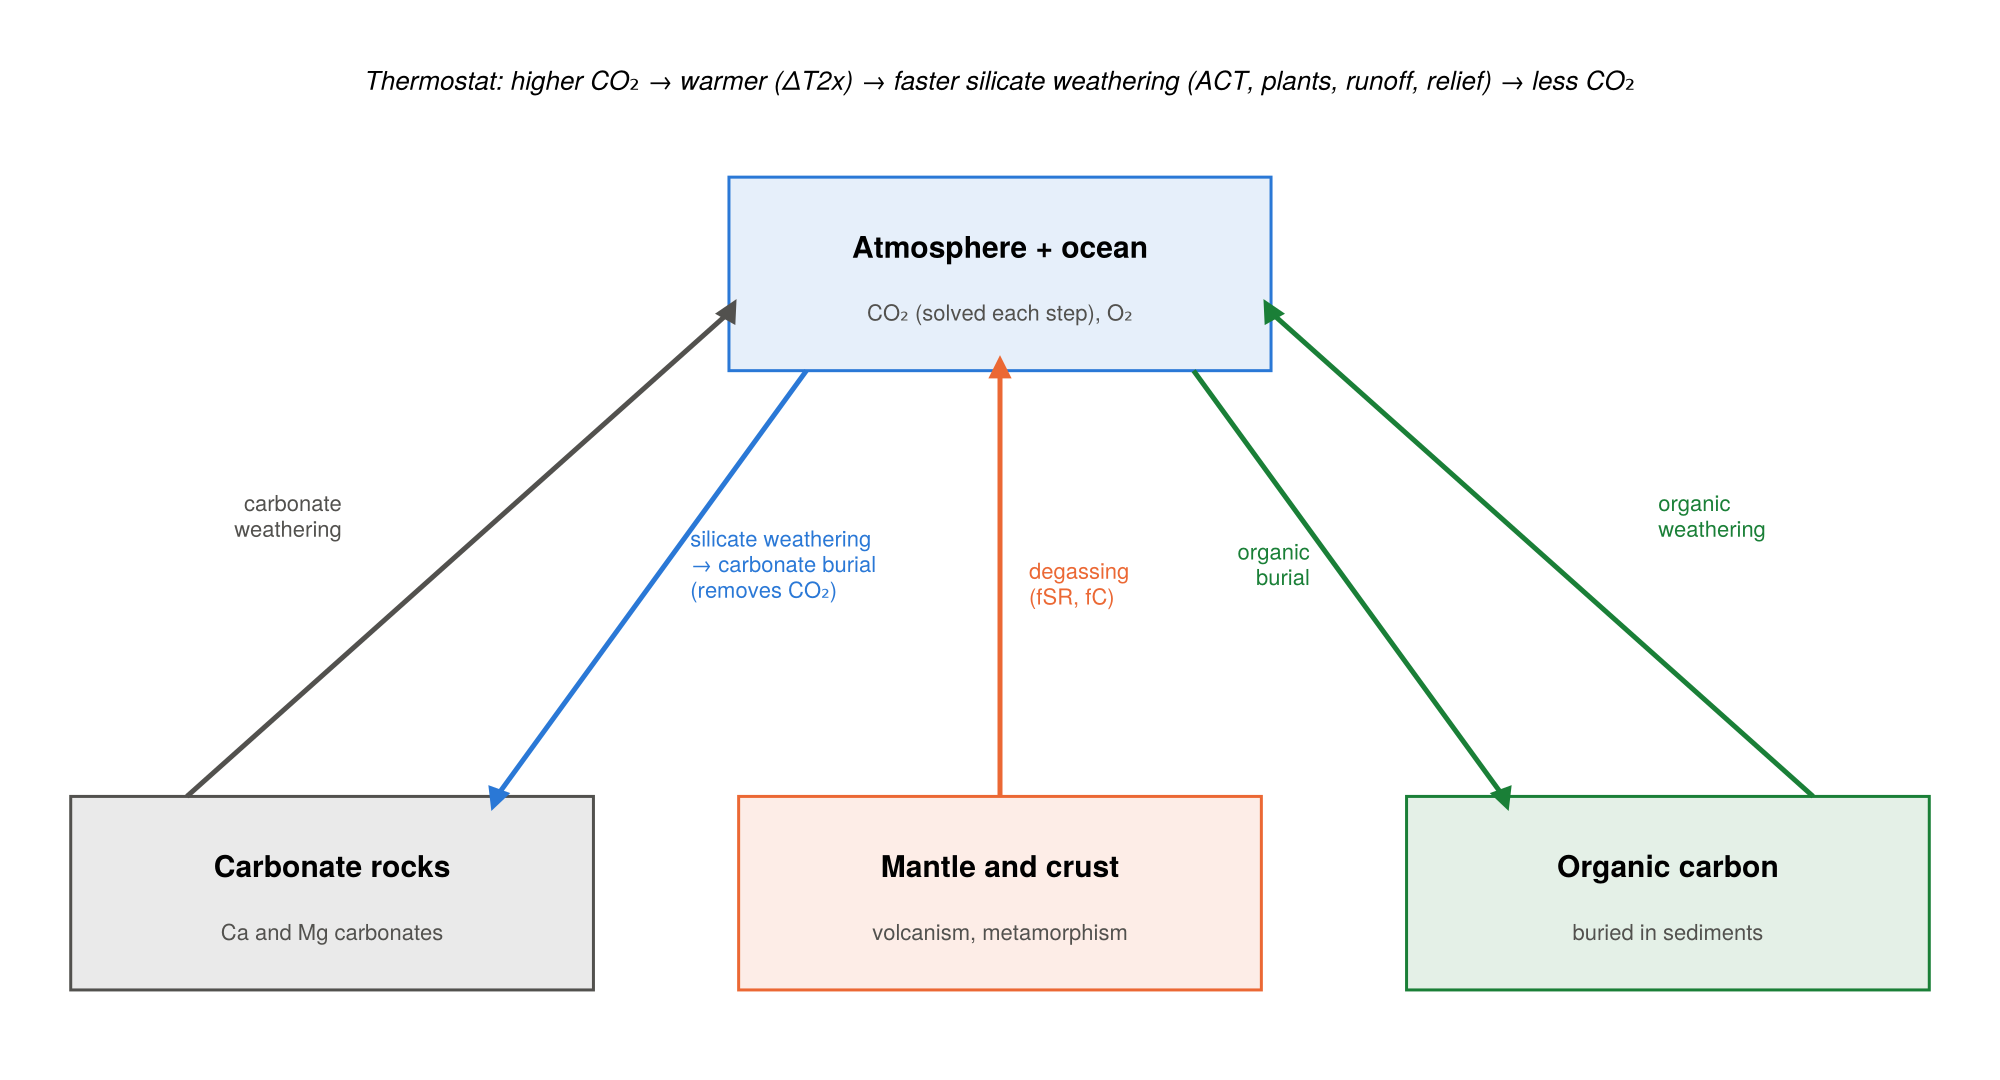

In [4]:
plot_carbon_cycle_schematic()

Each 10-million-year step runs these functions in order, each a direct port of a
few lines of the Fortran:

| step | Julia function | `run_geocarb.f90` lines |
|:--|:--|:--|
| climate sensitivity factor (glacial intervals, optional ΔT2x ramp) | `gcm_factor` | 309–315 |
| effect of plants on weathering | `vegetation_fE`, `carbonate_fBB` | 319–359 |
| weathering and degassing fluxes | `source_fluxes` | 363–378 |
| isotope fractionation and burial | `isotope_fractionations`, `burial_fluxes` | 381–390 |
| weathering of volcanic rocks (Sr isotopes) | `volcanic_weathering` | 393–400 |
| atmospheric O₂ | `update_oxygen` | 403–405 |
| silicate weathering required by mass balance | `silicate_weathering_no_climate` | 416 |
| damped Newton solve for CO₂ | `solve_rco2` | 431–521 |
| reservoir and isotope updates | `update_reservoirs` | 529–545 |
| outputs and failure checks | `run_geocarb!` | 547–566 |

### 1.4 Inputs

The model has **56 constant parameters** and **12 time-varying forcings**. Their
priors come with the package, in `data/`. The prior file says which constants are
calibrated (drawn from their prior) and which stay fixed at their mean; the table
lists the calibrated ones of `GEOCARB_input_summaries_calib_all.csv`, the file used
throughout.

In [5]:
table = read_prior_table(PRIOR_FILE)
tprior = read_time_arrays(ARRAY_FILE)
prior_table_html(table)

parameter,prior,mean,2σ,bounds,units,meaning
ACT,gaussian,0.09,0.045,"[0, Inf]",1/K,Activation energy for dissolution of Mg- and Ca-silicates on land (0.03 ≈ 20 kJ/mol; 0.08 ≈ 55 kJ/mol; Berner 2004 p. 28)
ACTcarb,gaussian,0.087,0.0435,"[0, Inf]",1/K,Activation energy for dissolution of carbonates on land
VNV,gaussian,5,2.5,"[0, Inf]",-,Rate of chemical weathering in volcanic silicate rocks relative to non-volcanic silicate rocks
NV,gaussian,0.0075,0.00375,"[0, Inf]",-,Coefficient relating physical erosion to the mean 87Sr/86Sr of non-volcanic silicate rocks
exp_NV,gaussian,0.67,0.335,"[0, Inf]",-,Exponent relating physical erosion to the mean 87Sr/86Sr of non-volcanic silicate rocks
LIFE,gaussian,0.25,0.125,"[0, Inf]",-,Rate of chemical weathering in a minimally vegetated world relative to the present (angiosperm-dominated) world
GYM,gaussian,0.875,0.4156,"[0, Inf]",-,Rate of chemical weathering by gymnosperms relative to angiosperms
FERT,gaussian,0.4,0.2,"[0, 1]",-,"Exponent for the fraction of vegetation whose growth is stimulated by CO2, in [2RCO2/(1+RCO2)]^FERT"
exp_fnBb,gaussian,0.5,0.125,"[0, Inf]",-,Exponent for the effect of climate on silicate or carbonate weathering in the absence of vascular plants
deltaT2X,lognormal,3,2.5,"[1.5, Inf]",°C,Climate sensitivity (warming per CO2 doubling); deltaT2X = GCM·ln(2)


The forcings are time series: for example `fSR`, the seafloor spreading rate (which
sets volcanic degassing), `fR` (relief), `fA` (land area) and `GEOG` (temperature
change from palaeogeography). Each has a centre and an uncertainty at every step:

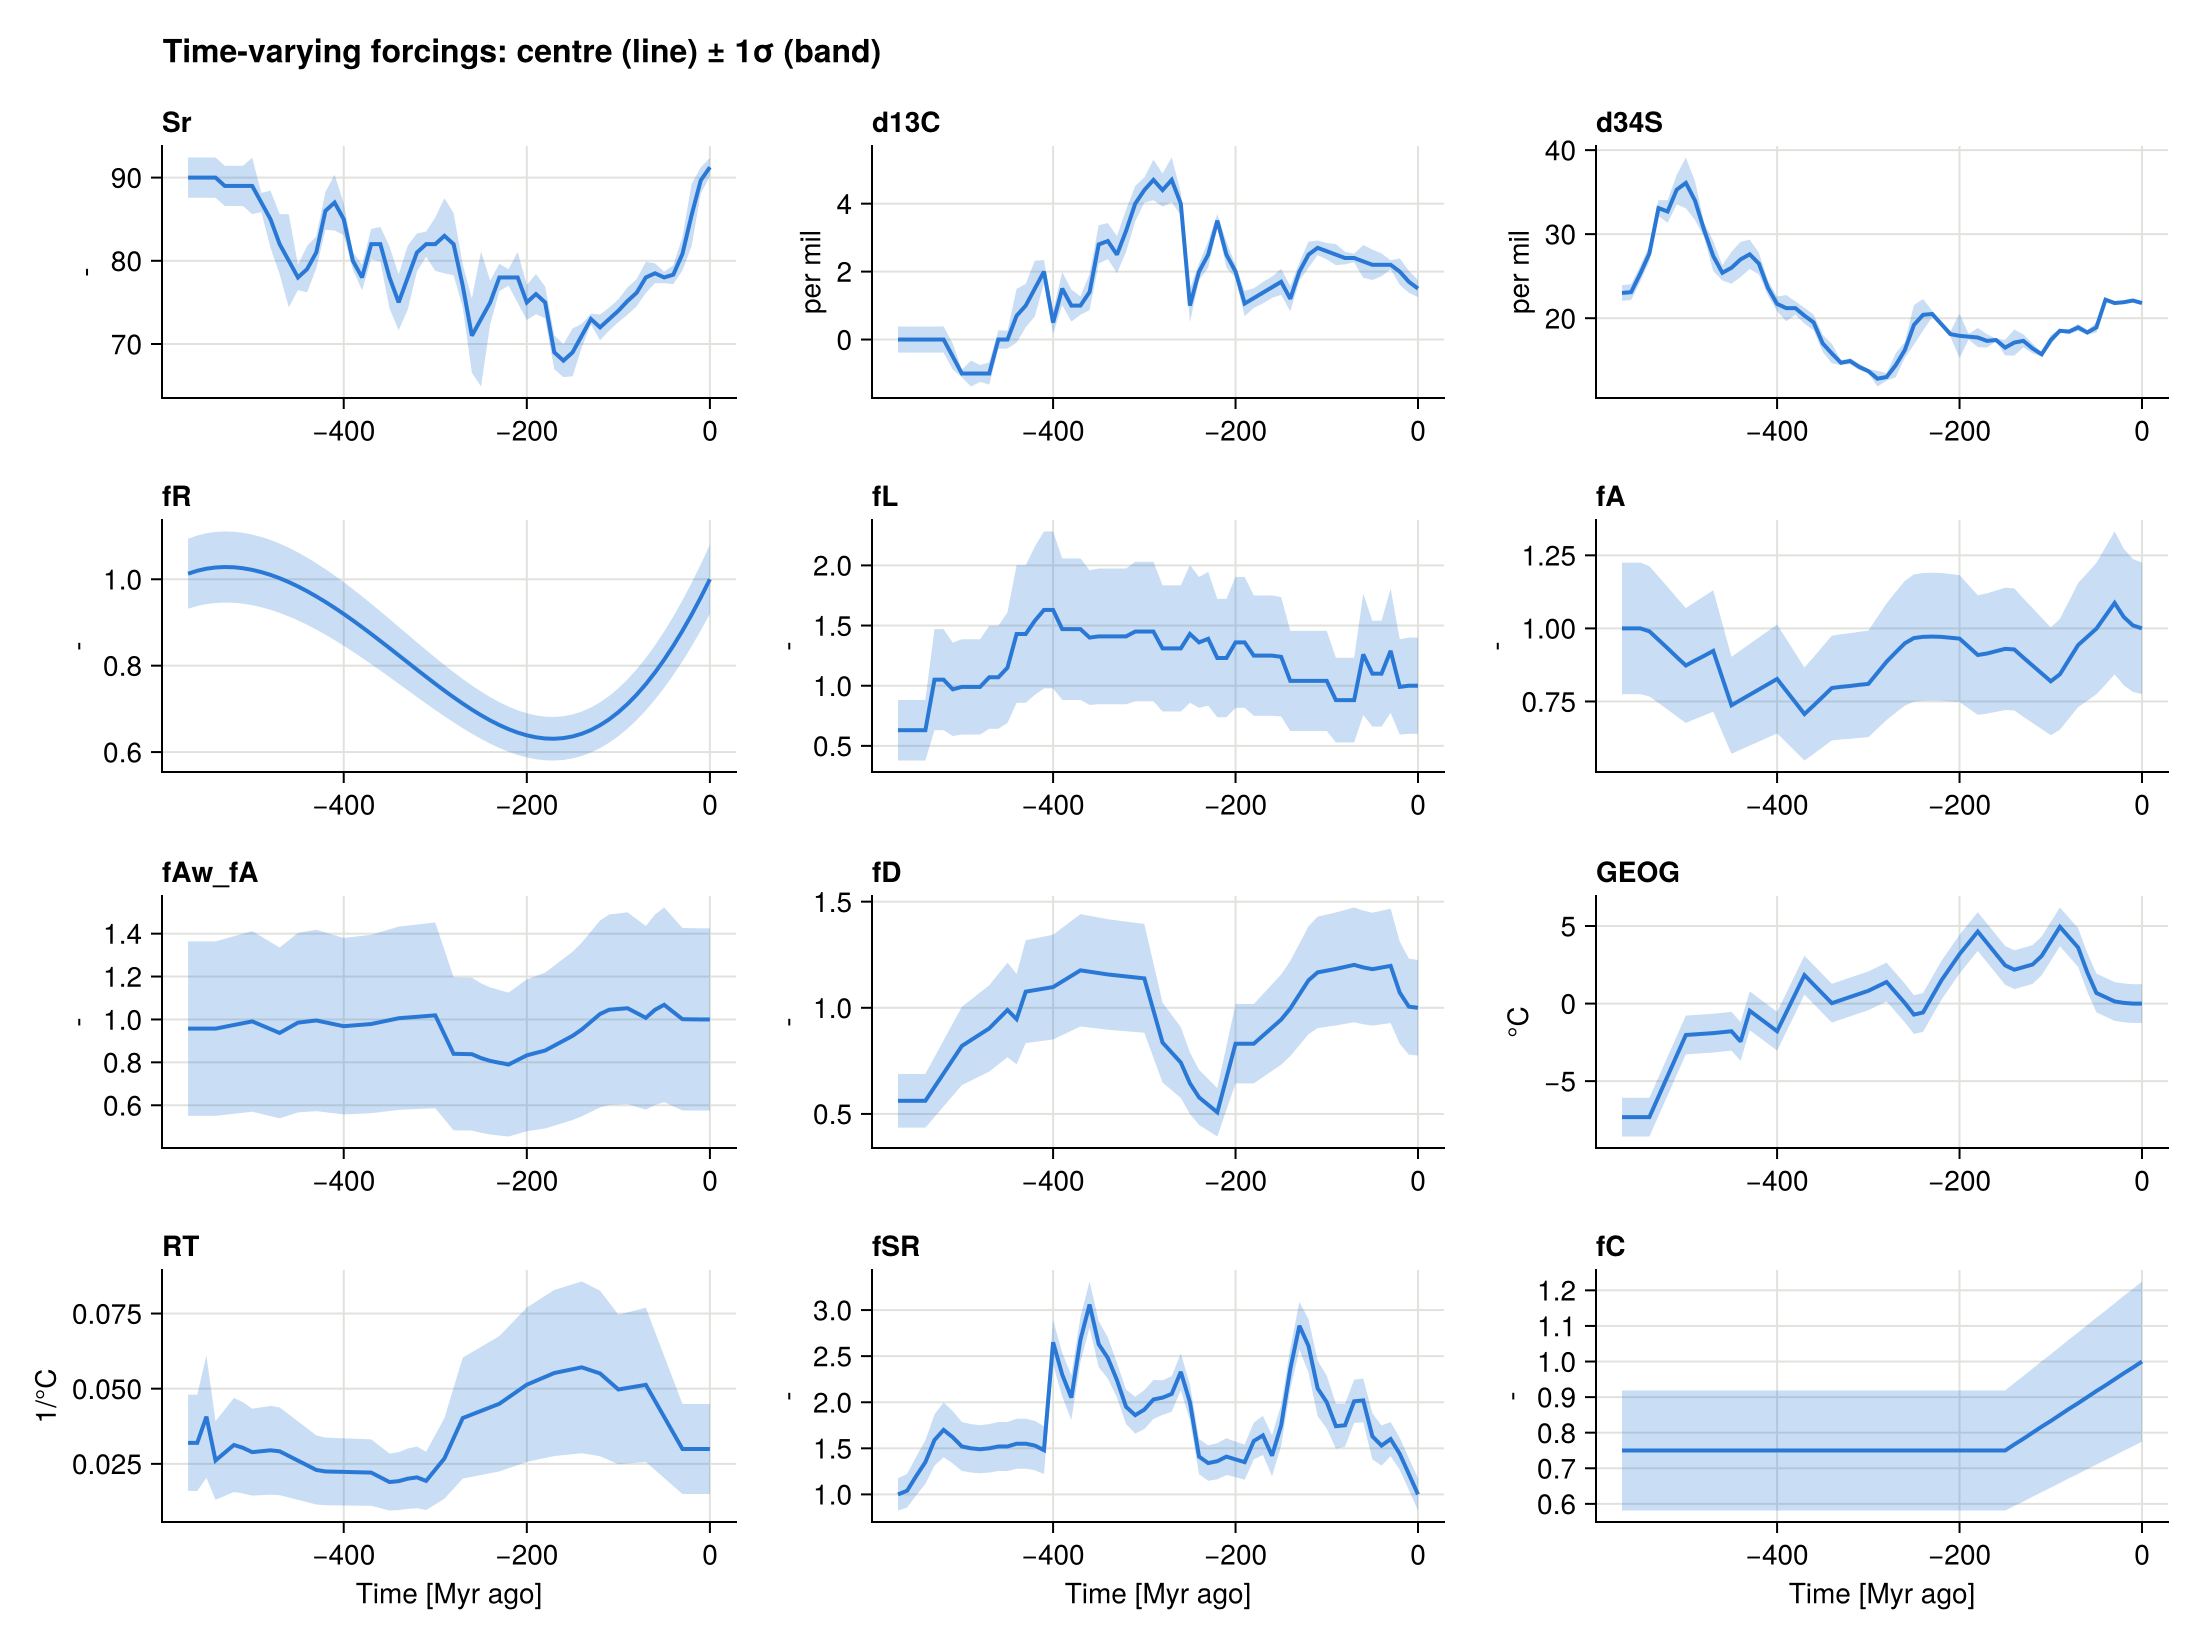

In [6]:
plot_forcings(tprior)

### 1.5 A first run

`run_geocarb` takes the constants and the forcings and returns CO₂ (ppmv), O₂ (%),
a temperature and a status for each step. Here everything is at its prior mean:

In [7]:
p = mean_constants(table)
f = tprior.center
r = run_geocarb(p, f)

GeocarbResult{Float64}: 58 steps, all converged
  present day: CO2 = 243.6674164797794 ppmv, O2 = 20.470467993407965 %, temp = -0.2220884991757911 °C

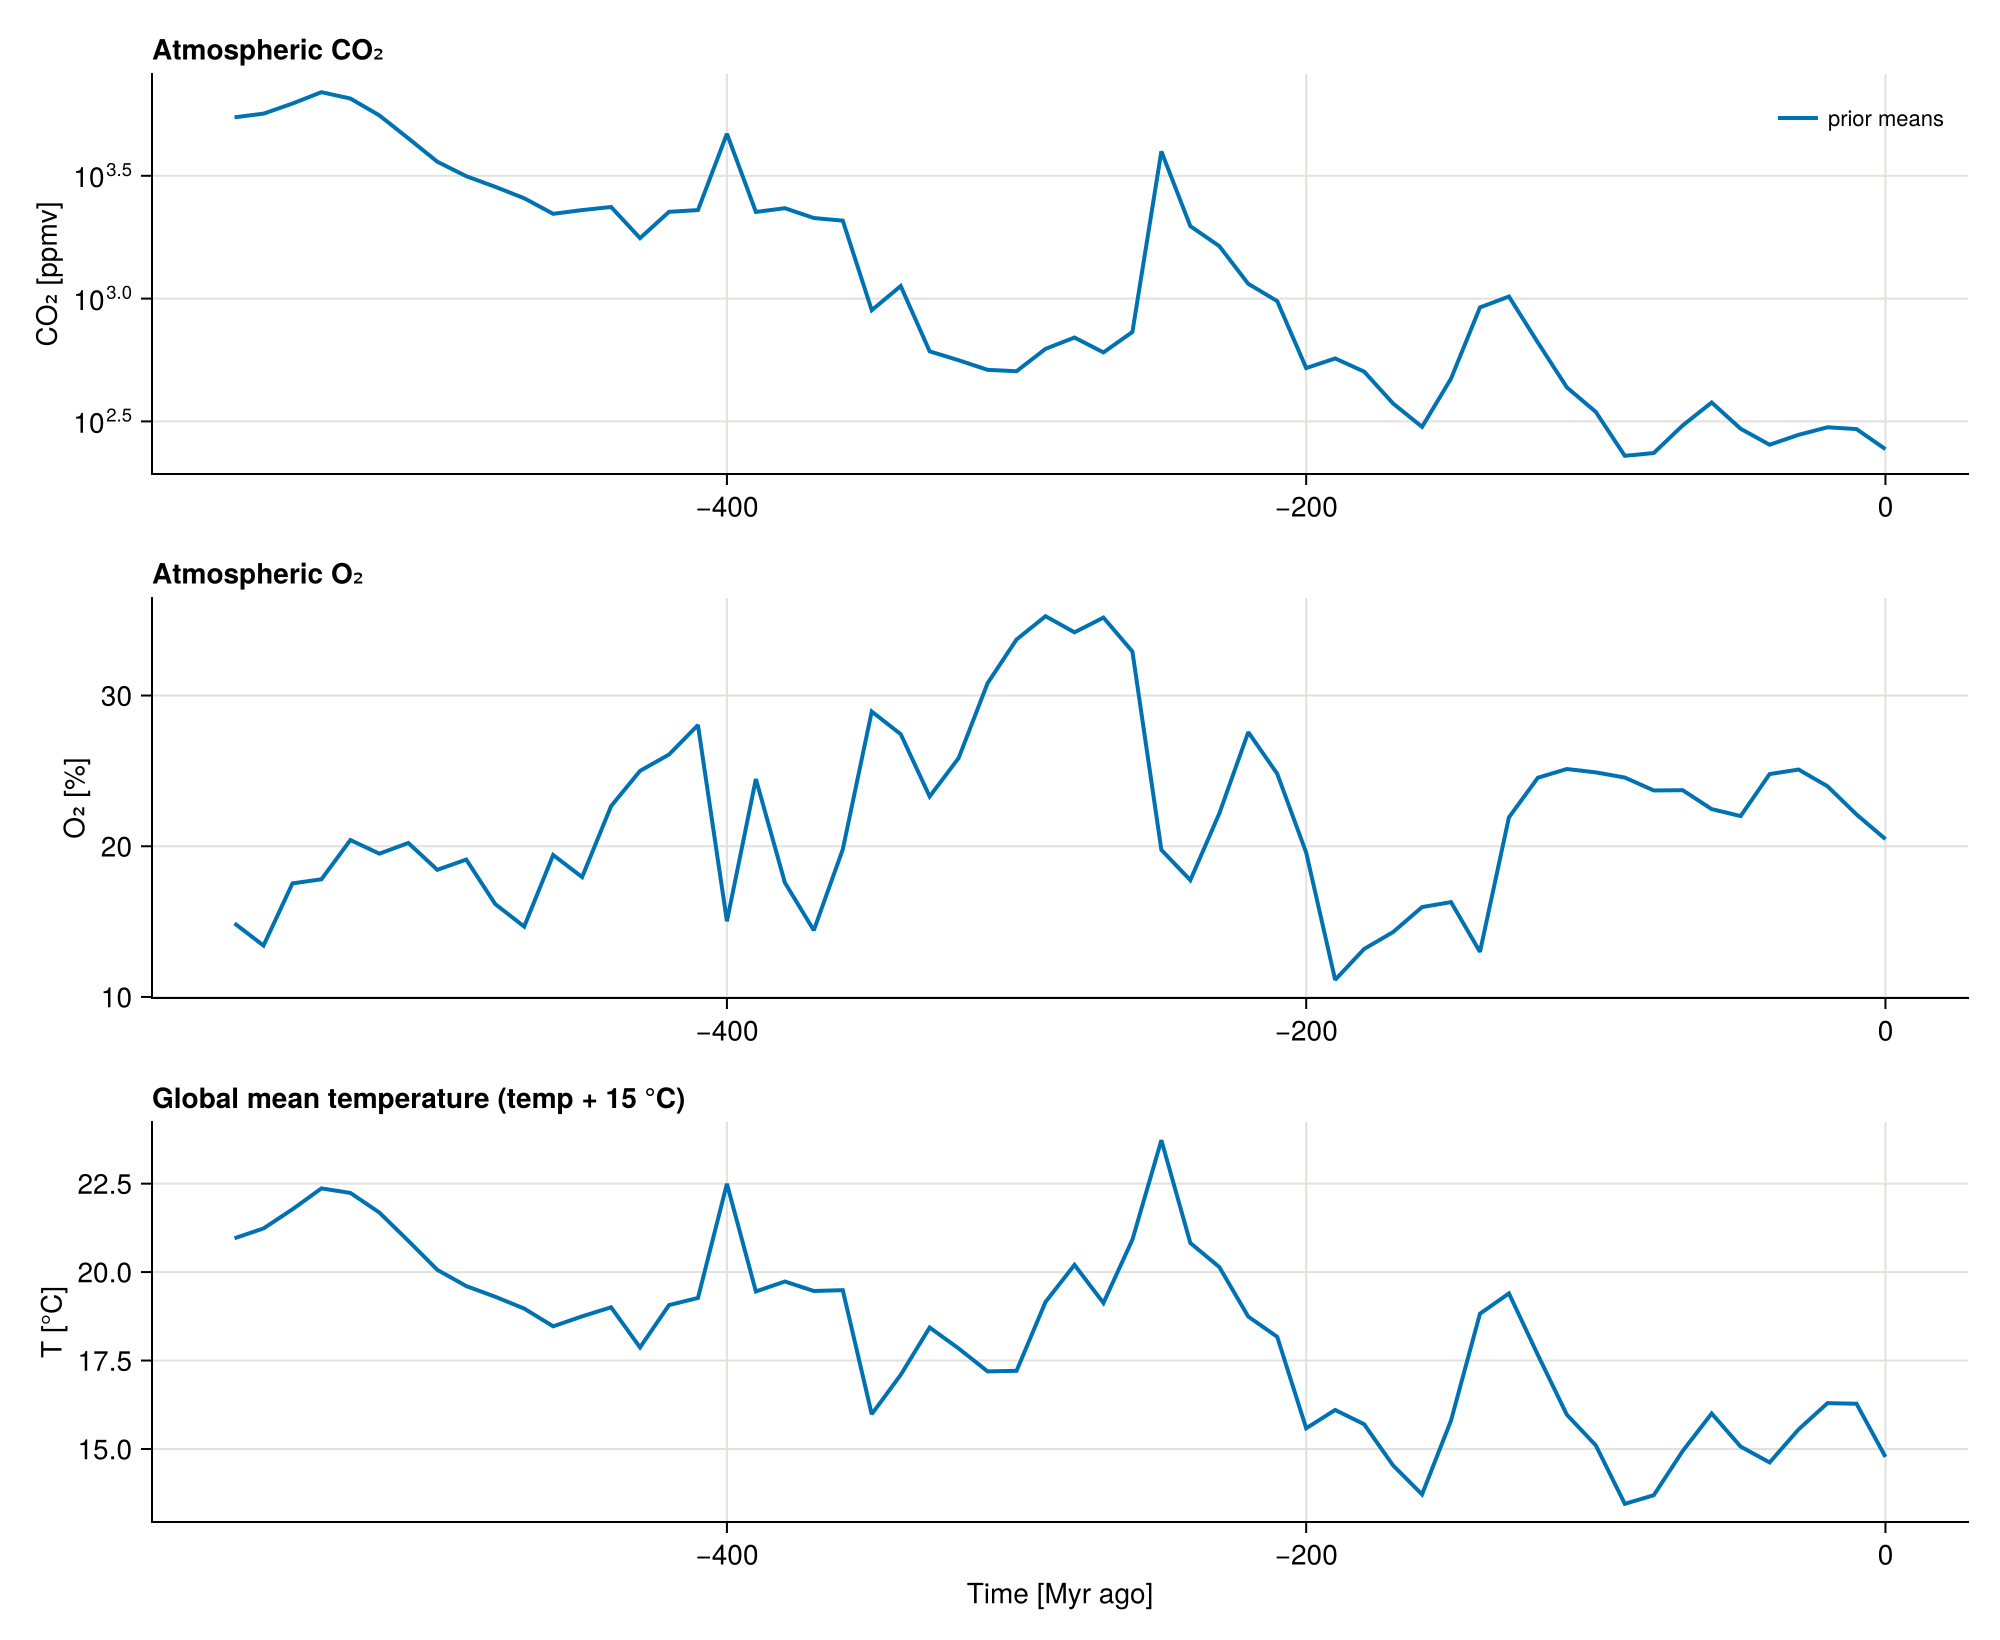

In [8]:
plot_runs(["prior means" => r])

The temperature drawn is `temperature(r)`, which is the model's `temp` plus 15 °C.
That is the quantity compared with the temperature windows in precalibration. The
documentation page *Temperature conventions* explains the other variants.

### 1.6 Climate sensitivity

`update` returns a copy of the constants with some values changed. Here ΔT2x goes
from 1.5 to 6 °C per doubling:

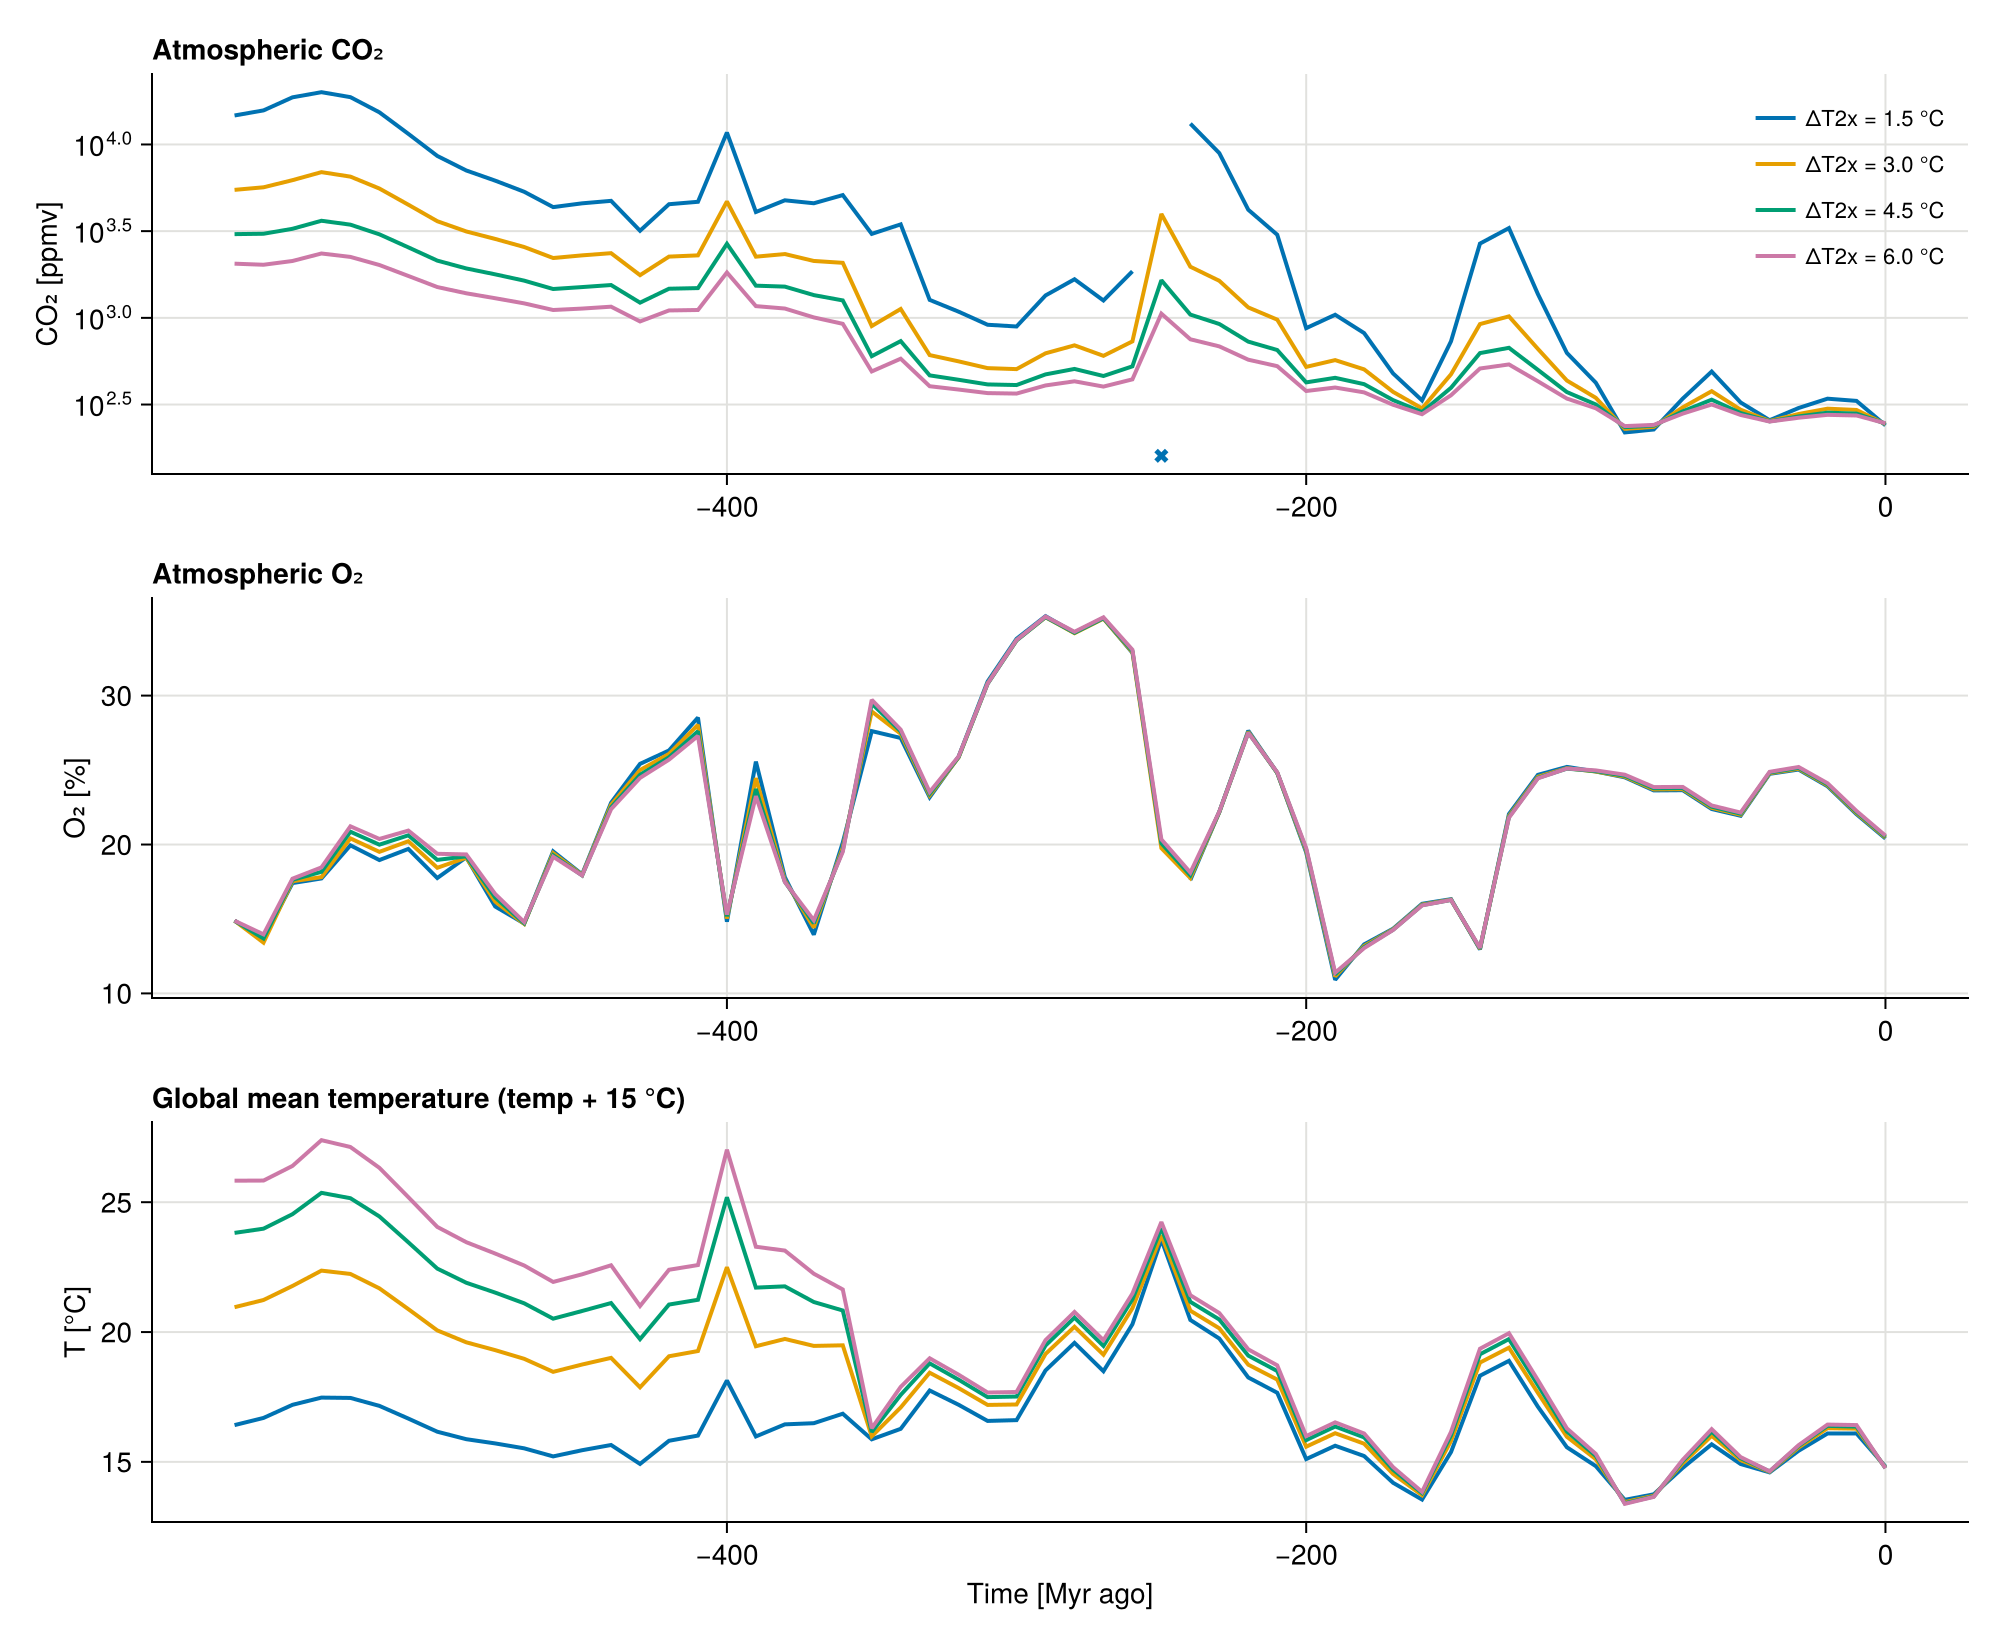

In [9]:
runs = ["ΔT2x = $(x) °C" => run_geocarb(update(p; deltaT2X=x), f) for x in (1.5, 3.0, 4.5, 6.0)]
plot_runs(runs)

Weathering responds to temperature, and temperature responds to CO₂ through ΔT2x.
With a more sensitive climate, a smaller change in CO₂ moves the temperature, and so
the weathering rate, far enough to balance the carbon budget. Compare how much the
CO₂ histories and the temperature histories spread as ΔT2x changes: the two records
respond to ΔT2x differently, which is why Wong et al. (2021) use CO₂ proxies and a
temperature reconstruction together.

### 1.7 When a step fails

The CO₂ solver can fail for some parameter values: it does not converge, produces a
NaN, or leaves the allowed CO₂ range. The original Fortran then writes `Inf` into
CO₂ and O₂ for that step **and keeps integrating** from that invalid state (finding
F-08 of the porting review). The Julia port keeps this behaviour so that results
match, and records why each step failed in `r.status`.

How often does that happen? Run the model on random draws from the priors (constants
by Latin hypercube, forcings by the inverse-Wishart sampler of the precalibration):

In [10]:
draws = prior_draws(N_DRAWS)
results = [run_geocarb(q, g) for (q, g) in draws]
callout(
    :note,
    "$(count(succeeded, results)) of $(length(results)) random prior draws have every step valid; " *
    "the rest fail at one step or more.",
)

> ℹ️ **Note.** 5 of 400 random prior draws have every step valid; the rest fail at one step or more.



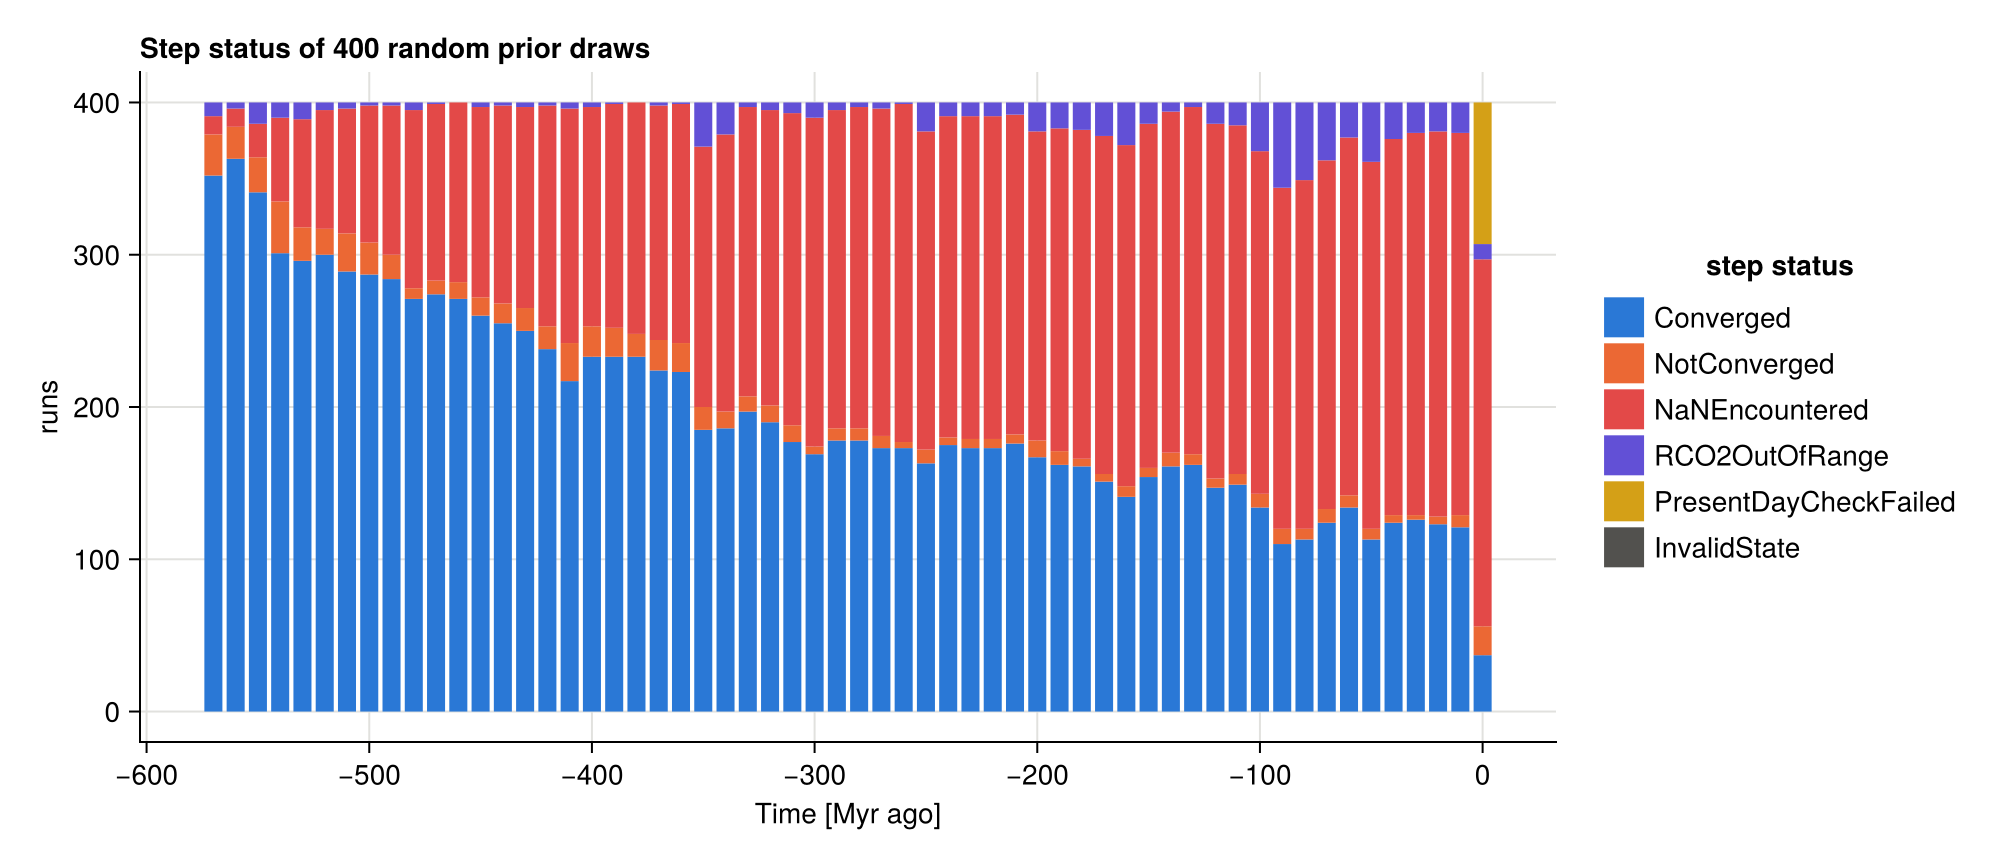

In [11]:
plot_step_status(results; title="Step status of $(length(results)) random prior draws")

Most prior draws fail somewhere (of the 1000 draws of the original R code compared
in Part 2, only 6 have every step valid), which is one reason precalibration rejects
so many samples. It also matters in Part 2: **after** a failed step the legacy model works
with invalid numbers, so tiny rounding differences grow there. That is why the
comparison is judged separately before and after a run's first failed step.

### 1.8 Options and the supplemental experiments

The original code had a second Fortran file, `run_geocarb_supp.f90`, for the
supplemental experiments of the paper. In Julia they are options of the one model:

| experiment | `ModelOptions` |
|:--|:--|
| control | defaults |
| gym | `gym_factor = 0.25` |
| timing | `gym_angio_transition = (110, 60)` |
| gym + timing | both |
| ΔT2x ramp | `dT2X_ramp = true` |
| gym + timing + ΔT2x ramp | all three |

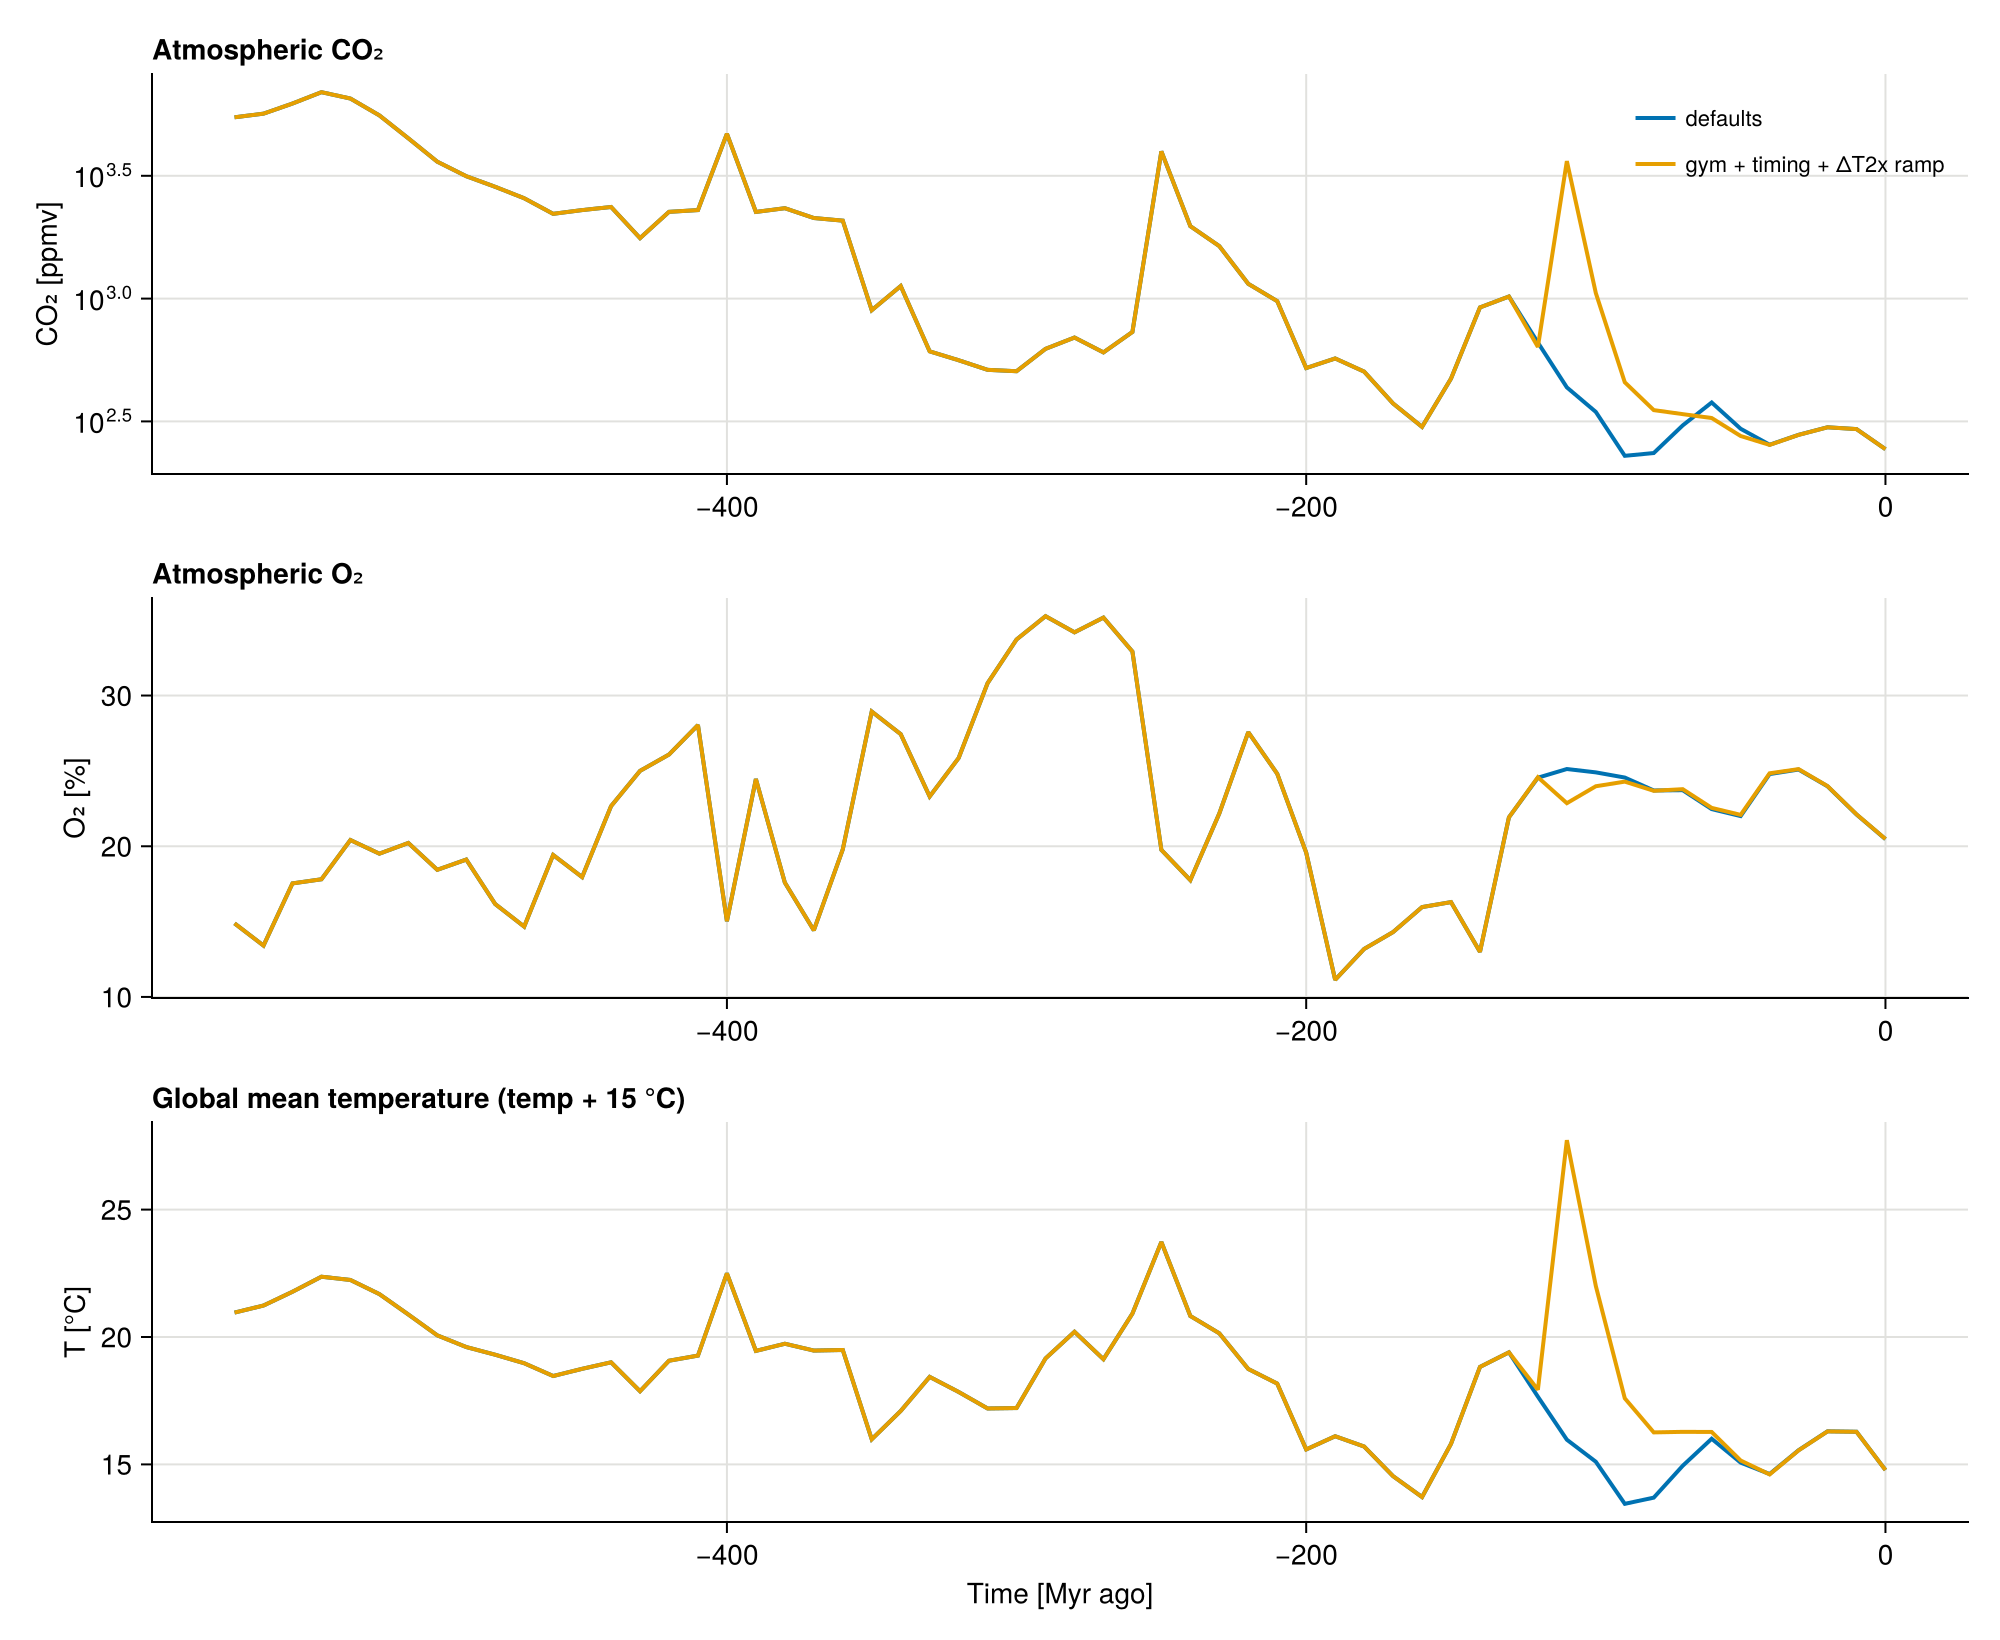

In [12]:
opts = ModelOptions(; gym_angio_transition=(110, 60), gym_factor=0.25, dT2X_ramp=true)
plot_runs(["defaults" => r, "gym + timing + ΔT2x ramp" => run_geocarb(p, f; options=opts)])

What the gymnosperm options change: the weathering factor of plants, `fE`, over
time (a figure from the package's plotting extension).

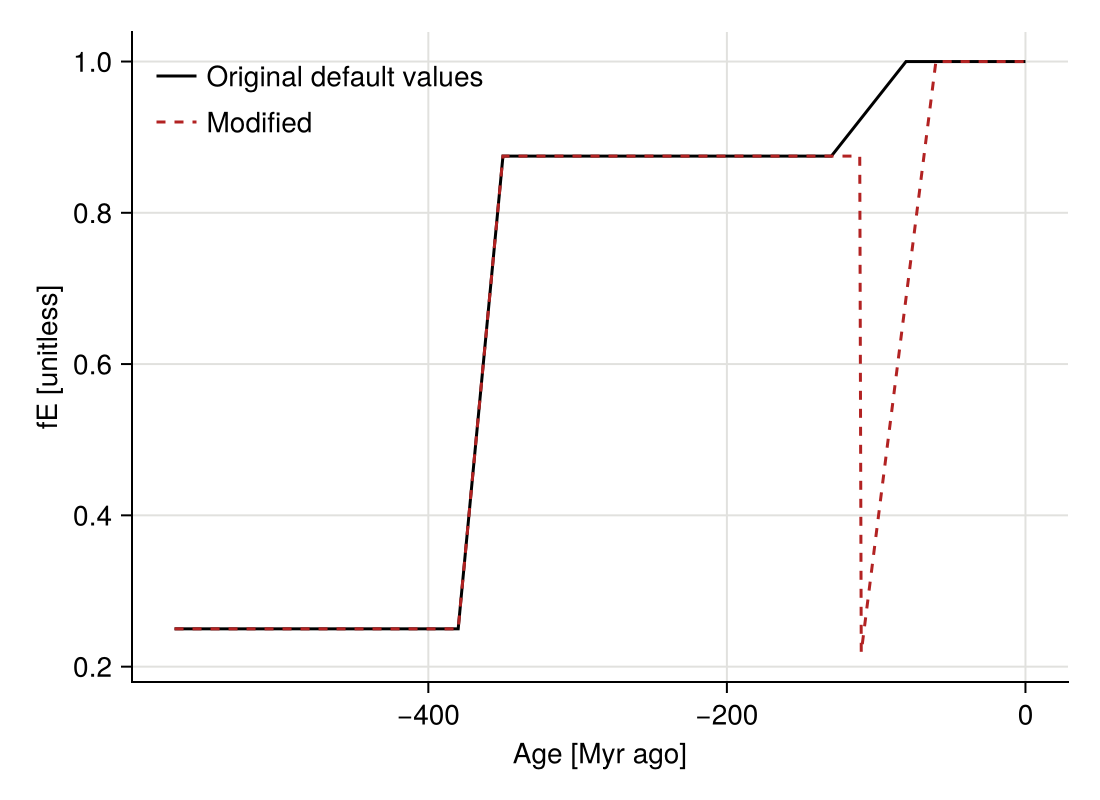

In [13]:
plot_gym_modification()

### 1.9 A case study: single-precision literals (finding F-05)

The compiled Fortran stores decimal constants such as `0.01`, `0.9` and `log(2.0)` in
**single** precision, because that is what gfortran does with default `REAL`
literals. Using the "cleaner" double-precision values would seem harmless. It is not:

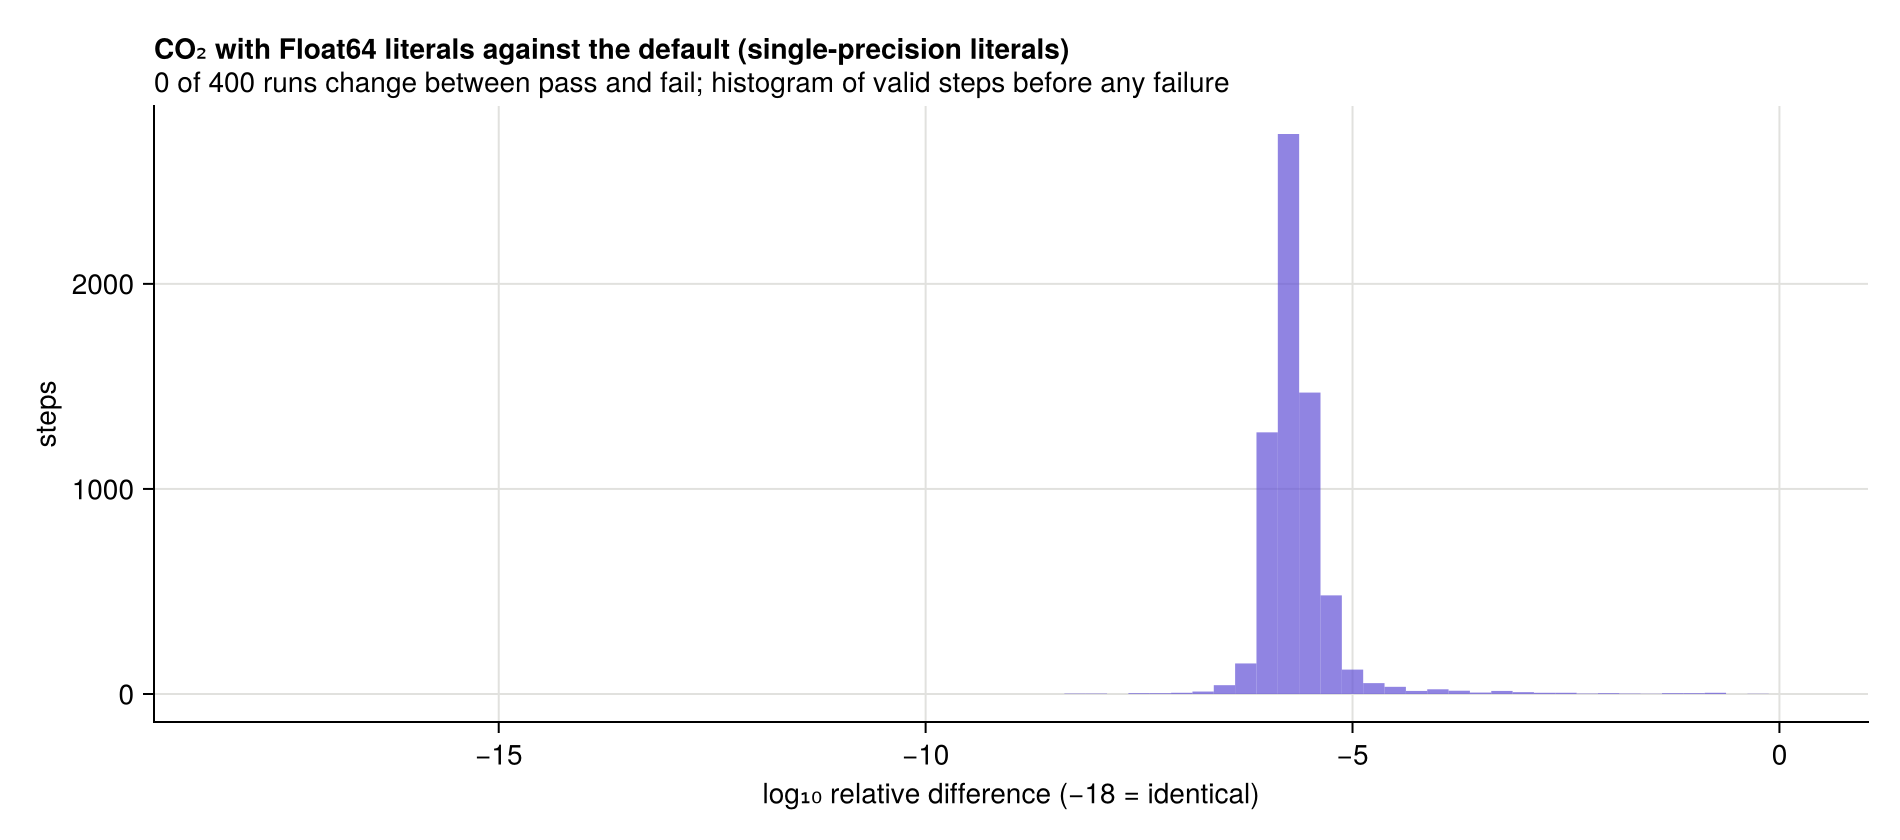

In [14]:
results64 = [run_geocarb(q, g; options=ModelOptions(; fortran_single_literals=false)) for (q, g) in draws]
plot_literal_effect(results, results64)

Some runs change from pass to fail or back, and valid steps move by far more than
rounding error. In the 1000-sample comparison with the original code (Part 2), 101
runs flipped and CO₂ moved by up to 14 % in otherwise valid steps. So the port reproduces the single-precision literals by default
(`fortran_single_literals = true`), and `false` is documented as a model change, not
a precision improvement.

### 1.10 Windows and % outbound

Precalibration compares each run with windows at every step:

- **CO₂ windows** come from the proxy compilation of Foster et al. (2017): at each
  step, the envelope of the proxies within ±5 Myr and their uncertainties;
- **temperature windows** come from the reconstruction of Mills et al. (2019).

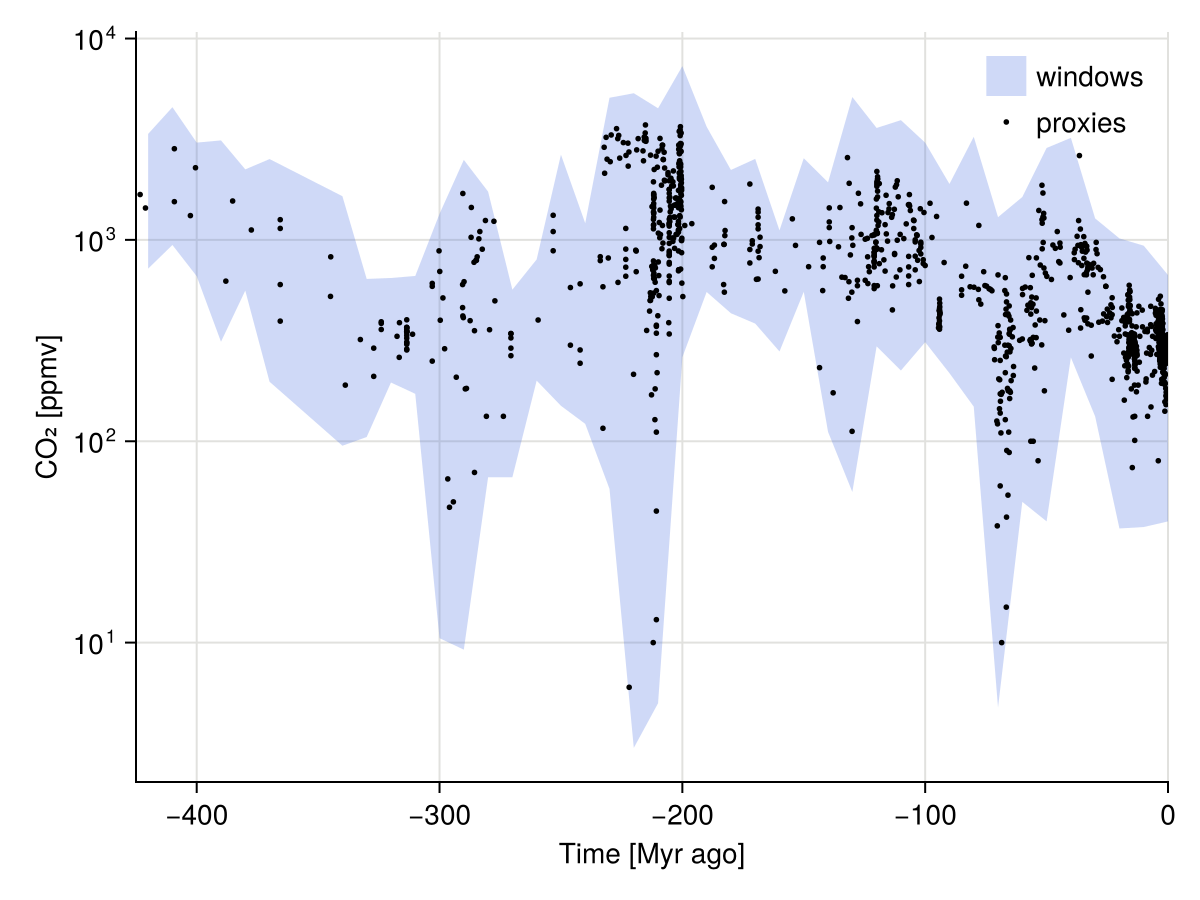

In [15]:
proxy = read_proxy_data(PROXY_FILE)
cw = co2_windows(proxy, f.age)
tw = temperature_windows(read_temperature_data(TEMP_FILE), f.age)
plot_co2_windows_and_proxies(proxy, cw)

The run at the prior means, against both windows:

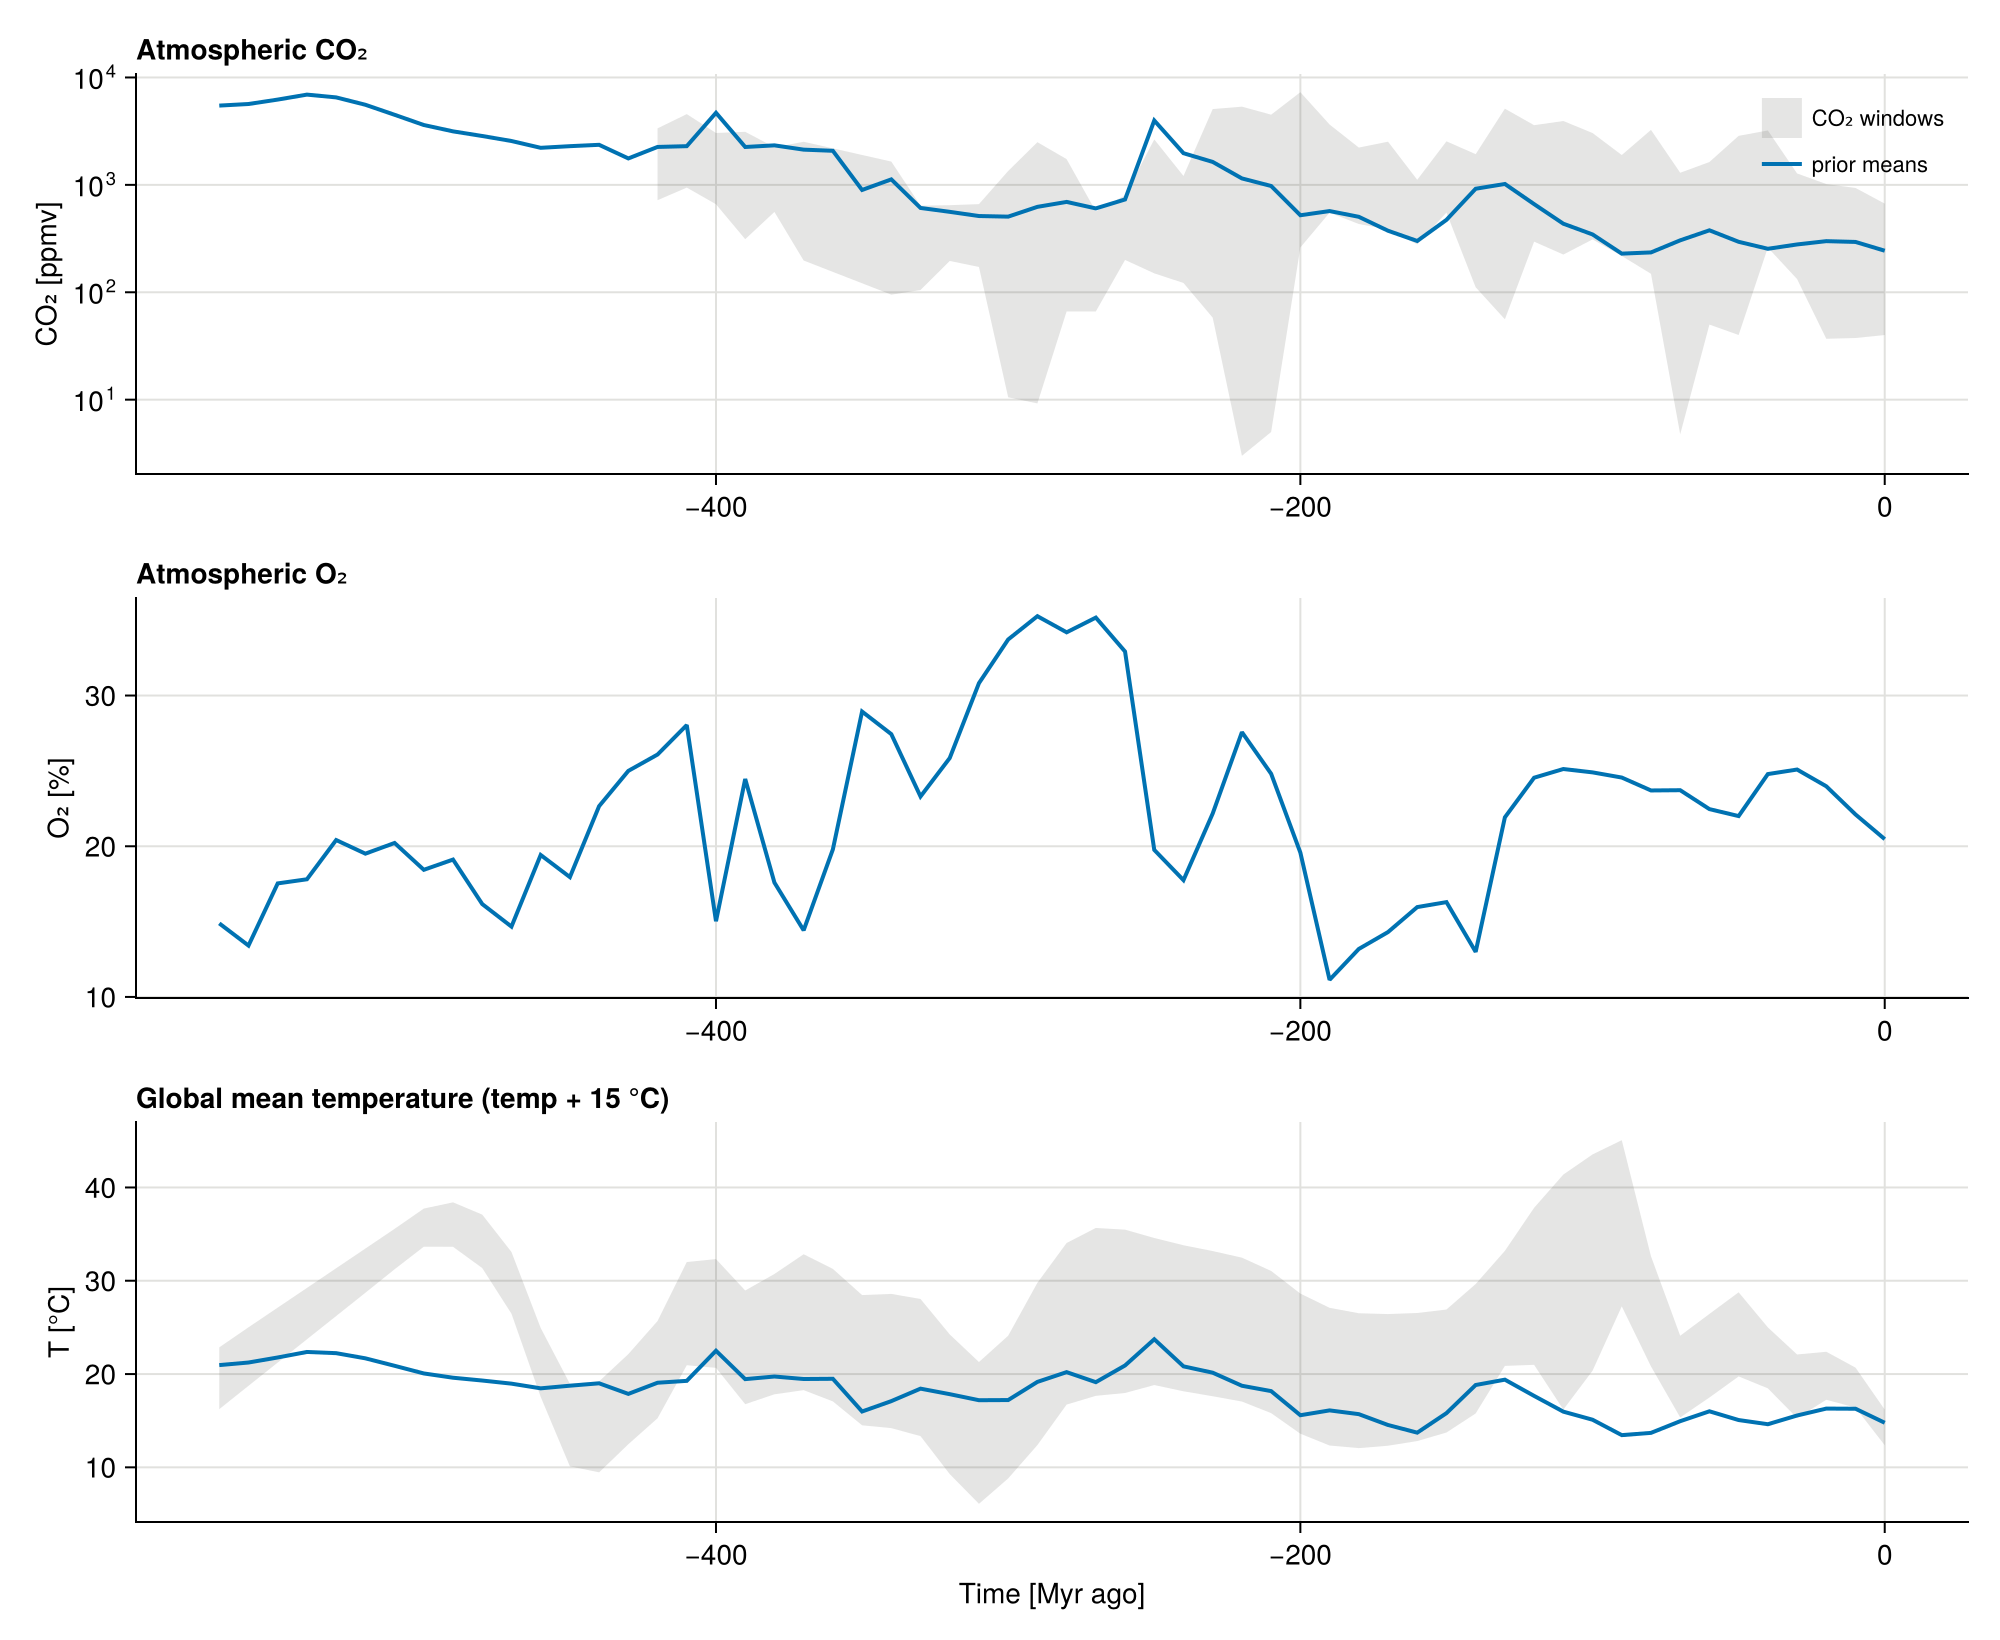

In [16]:
plot_runs(["prior means" => r]; cw, tw)

The **% outbound** is the fraction of steps outside the window. For CO₂ a failed
step makes it 1, because CO₂ is `Inf` there; temperature is not set to `Inf` on
failed steps, so its % outbound is unaffected (finding F-04). An experiment accepts
a run if its % outbound is at most a threshold, for CO₂, temperature or both.

In [17]:
callout(
    :note,
    @sprintf(
        "At the prior means: %.0f %% of steps outside the CO₂ windows, %.0f %% outside the temperature windows.",
        100 * legacy_percent_outbound(r.co2, cw),
        100 * percent_outbound(r, tw, :temp)
    ),
)

> ℹ️ **Note.** At the prior means: 14 % of steps outside the CO₂ windows, 36 % outside the temperature windows.



### 1.11 A small precalibration

Experiments are TOML files. `experiments/example_small.toml` is a quick one: up to
20 000 simulations, stopping once 1000 runs are accepted with at most 50 % outbound
for both CO₂ and temperature:

In [18]:
print(read(joinpath(ROOT, "experiments", "example_small.toml"), String))

# A small experiment that finishes in about a minute: a quick way to check an
# installation or to try out options. Increase n_sample for real results.

name        = "example_small"
description = "Small CO2 + temperature precalibration at 50 % outbound"
constraint  = "both"
threshold   = 0.5
seed        = 42
n_sample     = 20_000
n_per_chunk  = 2_000
n_accept_min = 1_000
output_dir   = "results/example"


Its `output_dir` is `results/example` inside the repository. The notebook points it
at a temporary folder instead, so running the notebook never writes into the
repository. (In quick mode the experiment is also made smaller.)

In [19]:
cfg = only(load_experiments(joinpath(ROOT, "experiments", "example_small.toml")))
quick = FAST ? (; n_sample=6_000, n_per_chunk=1_000, n_accept_min=150) : (;)
cfg = with_overrides(cfg; output_dir=mktempdir(), quick...)
println("results will be written to ", joinpath(cfg.output_dir, cfg.tag))

results will be written to /var/folders/10/j7h_7z2111961_4wxznz7jq40000gr/T/jl_9QmDHY/ct_out50


`run_precalibration` runs the chunks in parallel on all threads of this session. The
result does not depend on the number of threads: each chunk has its own random
stream, and chunks are combined in order. This takes about a minute.

In [20]:
res = run_precalibration(cfg)

[ Info: precalibration ct_out50: chunks 1:4 of 10, 8000 simulated, 76 accepted
[ Info: precalibration ct_out50: chunks 1:8 of 10, 16000 simulated, 149 accepted
[ Info: precalibration ct_out50: chunks 1:10 of 10, 20000 simulated, 180 accepted


PrecalibrationResult "ct_out50": 180 accepted of 20000 simulated
  age grid: 58 steps; covariances not stored

In [21]:
resdir = joinpath(cfg.output_dir, cfg.tag)
save_result(joinpath(resdir, "result.jld2"), res)
written = write_summary_csvs(resdir, res)
println("saved:\n  ", join(vcat(joinpath(resdir, "result.jld2"), written), "\n  "))

saved:
  /var/folders/10/j7h_7z2111961_4wxznz7jq40000gr/T/jl_9QmDHY/ct_out50/result.jld2
  /var/folders/10/j7h_7z2111961_4wxznz7jq40000gr/T/jl_9QmDHY/ct_out50/constants.csv
  /var/folders/10/j7h_7z2111961_4wxznz7jq40000gr/T/jl_9QmDHY/ct_out50/prcout.csv
  /var/folders/10/j7h_7z2111961_4wxznz7jq40000gr/T/jl_9QmDHY/ct_out50/provenance.toml


### 1.12 Its results

The headline numbers of the [Wong et al (2021) paper](https://doi.org/10.1038/s41467-021-23543-9) are quantiles of ΔT2x and of the glacial sensitivity ΔT2x·GLAC over the accepted samples:

In [22]:
tbl, exceed = n_accepted(res) > 0 ? sensitivity_table(res) : (nothing, nothing)
isnothing(tbl) ? callout(:warn, "No sample was accepted; increase `n_sample` in the cell above.") : tbl

,5 %,50 %,95 %
ΔT2x [°C],2.56,3.50,4.84
GLAC [–],1.38,2.03,2.80
ΔT2x·GLAC (glacial) [°C],4.51,7.07,10.54


In [23]:
isnothing(exceed) ? nothing : callout(:note, exceed)

> ℹ️ **Note.** Pr(ΔT2x ≥ 6 °C) = 0.006; Pr(ΔT2x ≥ 7 °C) = 0.006



Prior and posterior of ΔT2x, with the estimate of [Park & Royer (2011)](https://doi.org/10.2475/01.2011.01) for comparison:

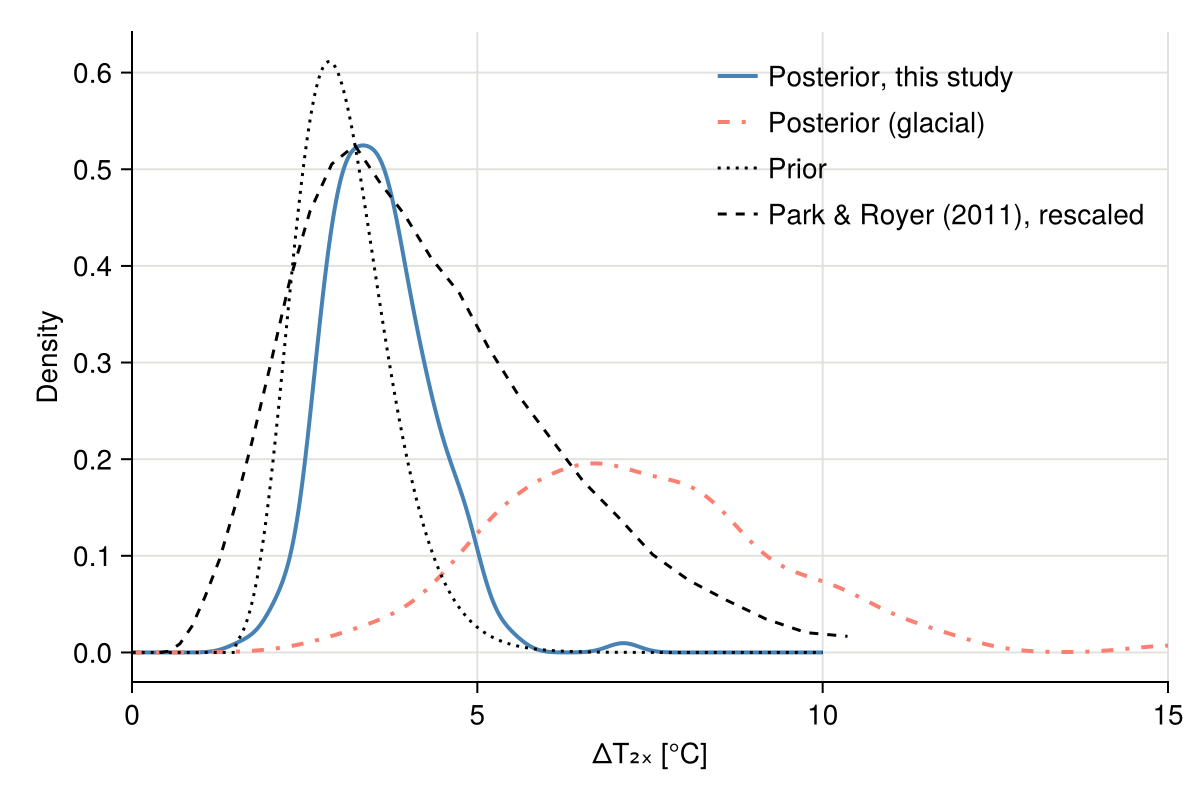

In [24]:
if n_accepted(res) > 0
    dT2X_prior = only(filter(q -> q.name == :deltaT2X, build_priors(table)))
    park_royer = read_park_royer_2011(datapath("ParkRoyer2011_Fig3_85varred.csv"))
    plot_deltaT2X_distributions(res; prior=dT2X_prior, park_royer)
end

The accepted runs (bands: 50, 90 and 95 % ranges) against the CO₂ proxies and the
temperature windows:

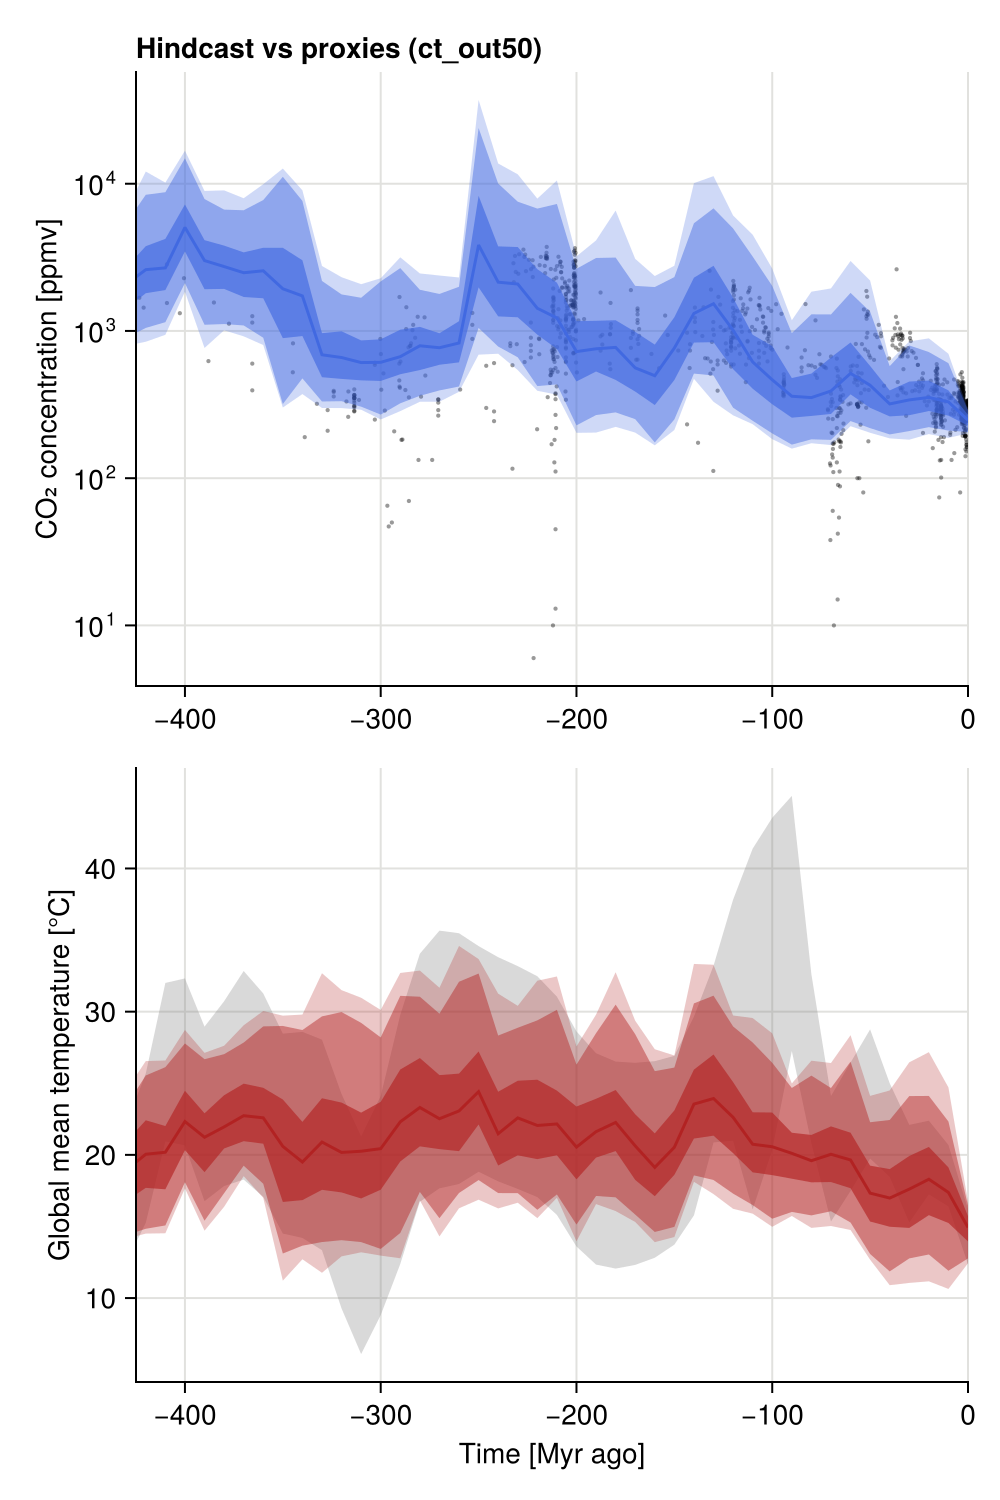

In [25]:
n_accepted(res) > 0 ? plot_model_vs_proxy(res, proxy, tw) : callout(:warn, "No accepted samples to plot.")

> ℹ️ **Note.** This is a small demonstration, not the paper's result: the paper's
> experiments use far more simulations and several thresholds (see
> `experiments/main/grid.toml`). The commands below reproduce them.

### 1.13 Going further

- **Reproduce [the paper](https://doi.org/10.1038/s41467-021-23543-9)**, from the repository folder (use `-t auto` for all threads):
  - `julia --project=. -t auto scripts/run_experiment.jl experiments/main/grid.toml`
  - `julia --project=. -t auto scripts/run_experiment.jl experiments/main/ct_out30_extra_seeds.toml`
  - the five files in `experiments/supplemental/` and the two in `experiments/cretaceous/`
  - then `scripts/analysis_main.jl`, `scripts/analysis_supplemental.jl` and `scripts/analysis_cretaceous.jl`
- `--dry-run` checks a configuration quickly; `--checkpoint` makes long runs resumable.
- **Write your own experiment**: copy a TOML file and change `constraint`,
  `threshold`, `n_sample`, `seed` or the `[model]` table (any `ModelOptions` keyword).
- **Documentation**: the pages *The model*, *Precalibration*, *Experiments* and
  *Porting notes* of the package documentation.

## Part 2: verification against the original R/Fortran code

### 2.1 What "the same answer" means

The Julia model is a line-by-line port, but its numbers cannot be **bit-for-bit**
identical to the Fortran's. Julia's `exp`, `log` and `^` and the C library that
gfortran uses occasionally round the last bit of a result differently. Even two
builds of the same Fortran (the main and supplemental libraries) differ by up to
8e-10 for that reason. So agreement is judged with tolerances, read here from
`test/tolerances.toml`, the single file both Fortran tests use:

In [51]:
tol = read_tolerances()
html_table(
    ["check", "requirement"],
    [
        ["positions of Inf and NaN (which steps fail)", "identical"],
        ["% outbound (decides acceptance)", "identical"],
        ["values before a run's first failed step", "relative difference ≤ " * fmt(tol.rtol_clean)],
        ["values at or after a run's first failed step", "relative difference ≤ " * fmt(tol.rtol_post)],
        ["absolute tolerance added to both", fmt(tol.atol)],
    ];
    caption="How the port is judged (test/tolerances.toml)",
)

check,requirement
positions of Inf and NaN (which steps fail),identical
% outbound (decides acceptance),identical
values before a run's first failed step,relative difference ≤ 1.00e-08
values at or after a run's first failed step,relative difference ≤ 1.00e-04
absolute tolerance added to both,1.00e-10


The relative difference of two values `a` and `b` is their difference divided by the
larger of the two magnitudes, after allowing the absolute tolerance.

> ℹ️ **Why two regions (finding F-08).** In a valid step the model is well
> conditioned: a last-bit difference stays a last-bit difference (below about 4e-9).
> When a step fails, the legacy code writes `Inf` into CO₂ and O₂ but **keeps
> integrating** from the invalid state. The steps after that are badly conditioned,
> and the same last-bit differences grow, up to 9.0e-6 relative so far (golden
> fixtures from the Fortran compiled in CI, November 2026). The limit after a
> failure is 1e-4, about 11 times the largest difference seen. A real porting
> error is still caught: it changes valid steps by far more than 1e-8, or moves a
> failure, or changes a % outbound, and all three are checked separately.

### 2.2 Three levels of evidence

The comparison can be made at three levels. They differ in what they need and in
what they serve to verify:

In [52]:
levels_table(env, RUN_LEVEL_B, RUN_LEVEL_C)

level,compares Julia against,needs,proves,does not prove,here
A golden master,"stored output of the compiled original Fortran (test/fixtures/fortran): 100 prior samples, main model and 6 supplemental variants",Julia only,"the Julia model reproduces the Fortran model at every step, on this machine and Julia version","the input pipeline, priors, windows or % outbound; inputs other than those 100 samples",will run
B replay,"inputs and outputs saved by an earlier run of the unmodified R/Fortran code (test/legacy_comparison/output, 1000 samples)",an earlier level-C run on this machine (the folder is not in git),"the whole Julia pipeline (input processing, prior transform, model, % outbound, supplemental variants) reproduces what the original code produced then","that the original code still runs, or runs the same way, here and now",– skipped (no stored exports on this machine)
C live,"the unmodified R/Fortran code in legacy/, run now","R ≥ 4.1 with lhs, CholWishart, abind, MASS; a Fortran compiler or compiled libraries","everything level B proves, against output produced now on this machine; also that R passed the inputs to the Fortran unchanged (direct ccall, bit for bit)",other operating systems (CI's Legacy workflow runs it on Linux),– skipped (needs R with its packages and a Fortran compiler; see Setup)


### 2.3 The test suite

The package's tests are grouped (`test/runtests.jl`); CI runs them on Linux, macOS
and Windows. Here each group runs with `Pkg.test()` in its own Julia process,
exactly as on the command line (`GROUP=unit julia --project=. -e "using Pkg; Pkg.test()"`).
Every process compiles the package once, so this takes several minutes.

| group | what it checks |
|:--|:--|
| `unit` | physics pieces, step-status invariants on 200 prior draws, options, input validation, zero allocations, Float32 and ForwardDiff inputs |
| `io` | the CSV reader, prior table, time arrays, proxies, temperature data |
| `sampling` | Latin hypercube strata, truncated priors (KS tests), inverse-Wishart degrees of freedom, sampler moments |
| `constraints` | CO₂ and temperature windows, % outbound |
| `workflow` | configuration files, the engine (stopping rule, determinism across thread counts, checkpoints), saving, analysis |
| `regression` | **level A**: the golden master against stored Fortran output |
| `quality` | Aqua.jl: stale dependencies, compat bounds, type piracy, ambiguities |
| `doctests` | the examples in the docstrings |

In [28]:
println("running ", length(TEST_GROUPS), " test groups:")
test_results = run_test_groups(TEST_GROUPS)
test_results_table(test_results)

running 8 test groups:
  unit         … passed (184 s)
  io           … passed (11 s)
  sampling     … passed (16 s)
  constraints  … passed (12 s)
  workflow     … passed (36 s)
  regression   … passed (13 s)
  quality      … passed (21 s)
  doctests     … passed (17 s)


group,result,pass,fail,error,broken,total,wall time
unit,✔ pass,191,0,0,0,191,184 s
io,✔ pass,48,0,0,0,48,11 s
sampling,✔ pass,40,0,0,0,40,16 s
constraints,✔ pass,24,0,0,0,24,12 s
workflow,✔ pass,103,0,0,0,103,36 s
regression,✔ pass,42,0,0,0,42,13 s
quality,✔ pass,11,0,0,0,11,21 s
doctests,✔ pass,1,0,0,0,1,17 s


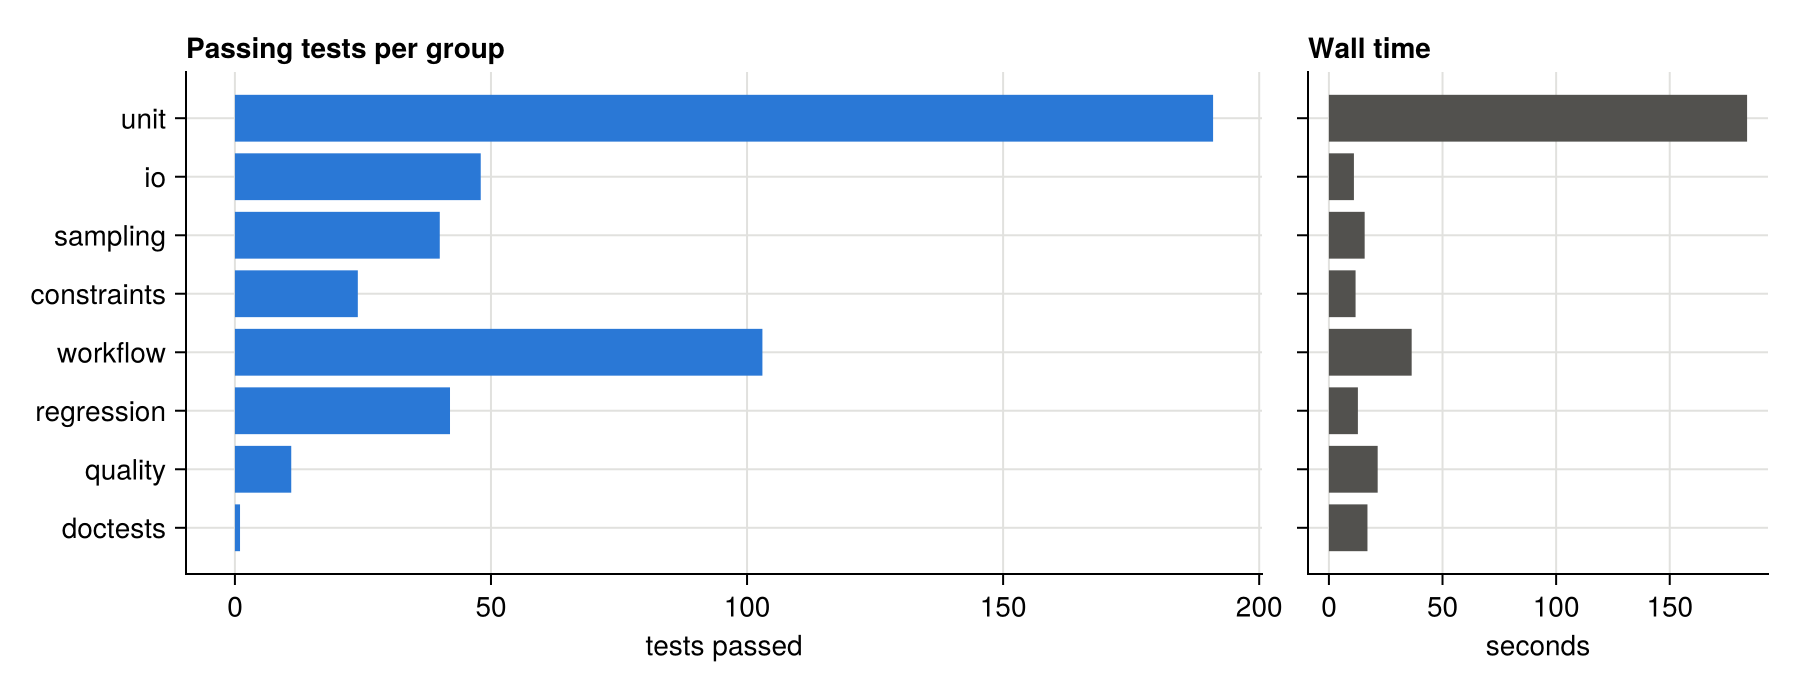

In [29]:
plot_test_results(test_results)

Each group's full output is in the log file named in `test_results`; for example
`test_results[1].log`.

### 2.4 Level A: the golden master

`test/fixtures/fortran/` holds inputs and outputs of the **compiled original
Fortran** for 100 prior samples, for the main model and the six supplemental
variants (produced by the unmodified R/Fortran code, see
`test/fixtures/README.md`). The `regression` group above checks them with
pass/fail. Here the same comparison is repeated with the numbers kept, so you can
see how close the agreement is, not only that it passes:

  Julia 1.12 has introduced more strict world age semantics for global bindings.
  !!! This code may malfunction under Revise.
  !!! This code will error in future versions of Julia.
Hint: Add an appropriate `invokelatest` around the access to this binding.
To make this warning an error, and hence obtain a stack trace, use `julia --depwarn=error`.
  Julia 1.12 has introduced more strict world age semantics for global bindings.
  !!! This code may malfunction under Revise.
  !!! This code will error in future versions of Julia.
Hint: Add an appropriate `invokelatest` around the access to this binding.
To make this warning an error, and hence obtain a stack trace, use `julia --depwarn=error`.
  Julia 1.12 has introduced more strict world age semantics for global bindings.
  !!! This code may malfunction under Revise.
  !!! This code will error in future versions of Julia.
Hint: Add an appropriate `invokelatest` around the access to this binding.
To make this warning an error, and hence o

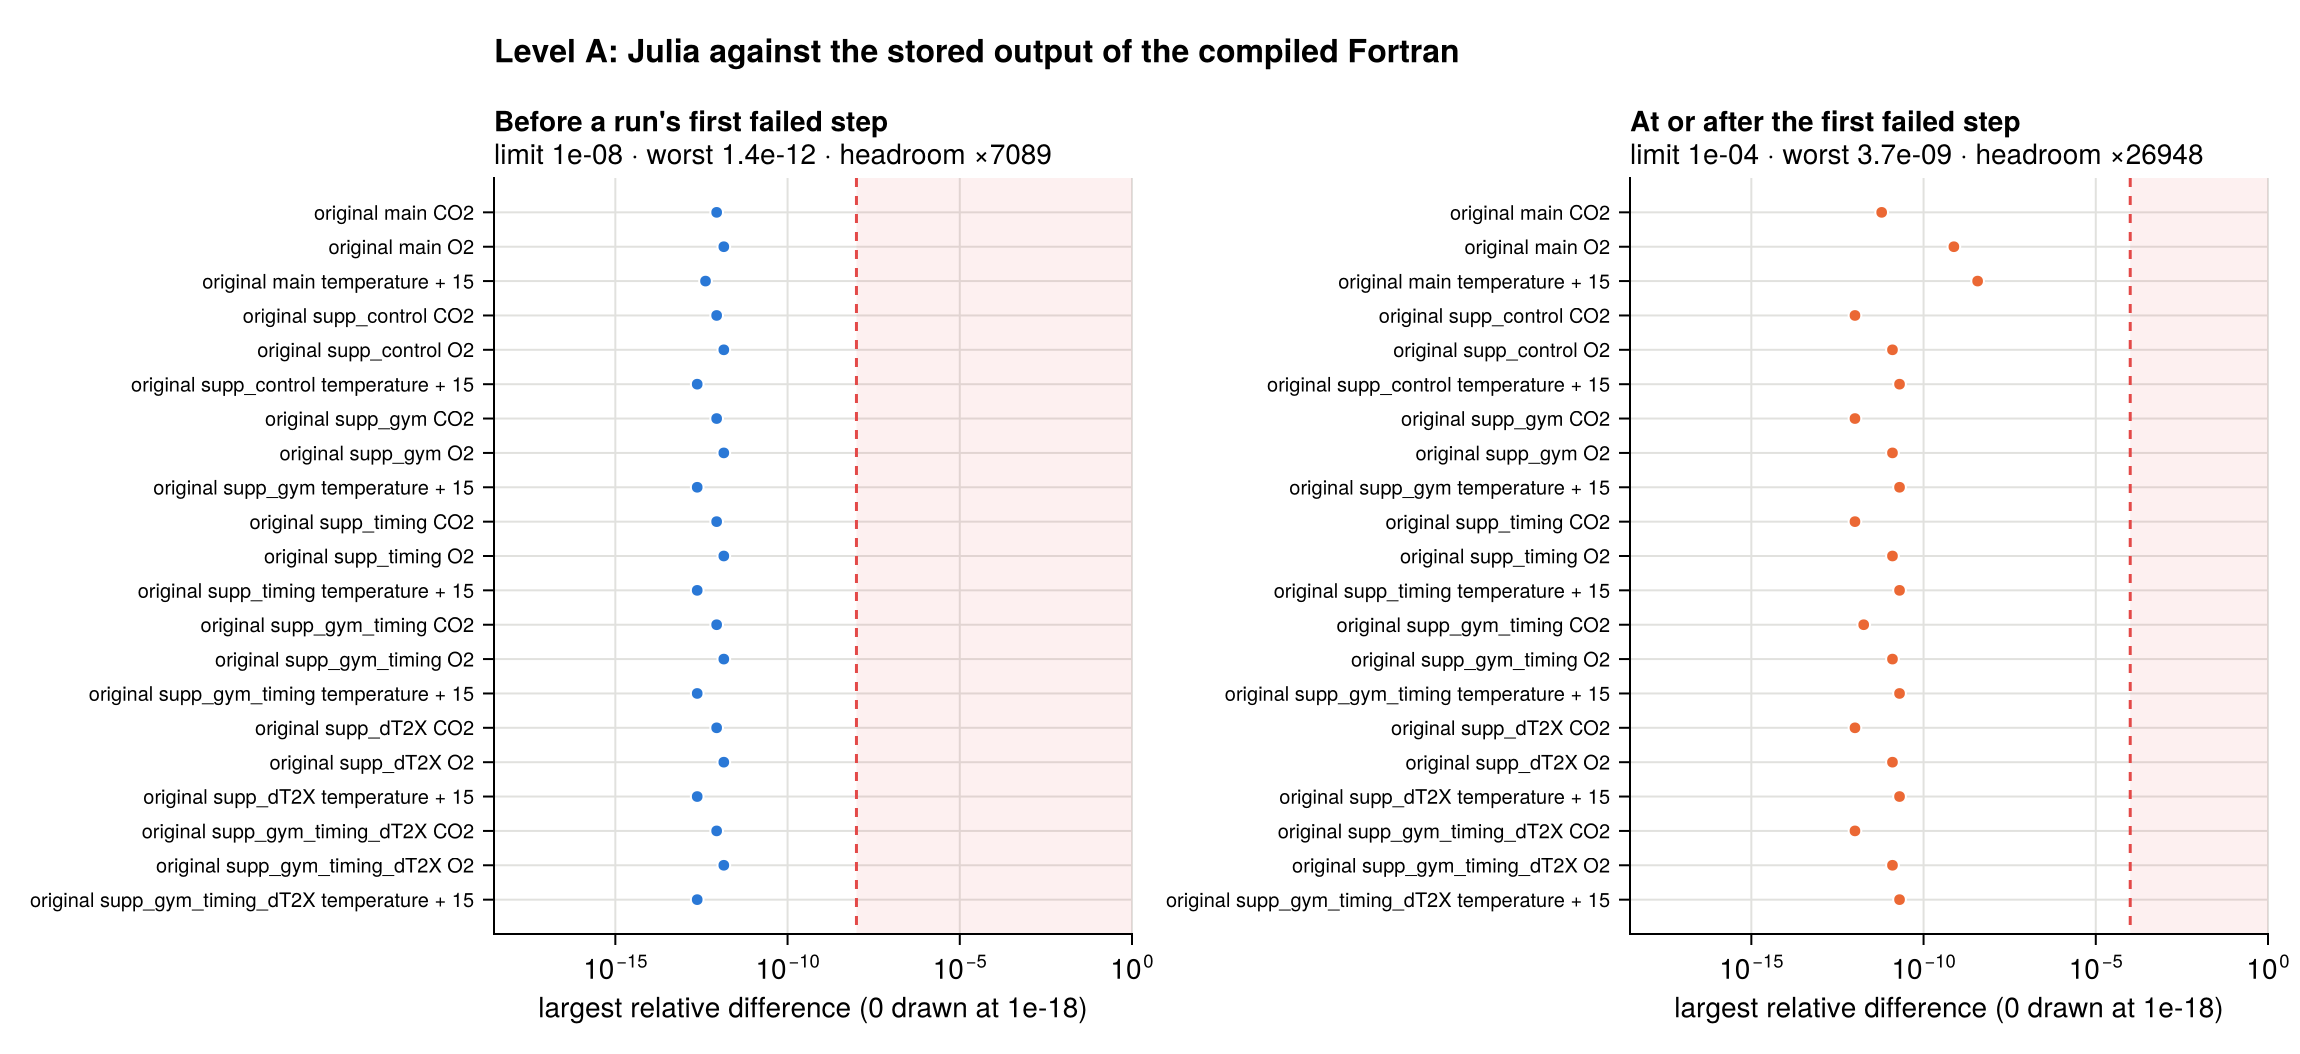

In [30]:
golden = golden_master_checks()
plot_headroom(golden; title="Level A: Julia against the stored output of the compiled Fortran")

How to read the figure: each row is one quantity of one model variant. The dot is
the largest relative difference over all its cells (runs × steps); the dashed line
is the tolerance; the shaded zone is where the check would fail. Left: cells before
a run's first failed step (limit 1e-8). Right: cells at or after it, where the
legacy code integrates from an invalid state (finding F-08, section 2.1) and the
limit is 1e-4. Rows labelled "pass/fail positions" are not drawn: they require the
failed steps to be in identical places, and their result is in the table.

In [31]:
checks_table(golden; collapsed="All $(length(golden)) level-A checks (click to expand)")

check,cells,largest rel. difference,tolerance,Inf/NaN mismatches,out of tolerance,
original main CO2: pass/fail (Inf/NaN) positions,5800,0,identical,0,0,✔ pass
original main CO2 [before any failure],1541,8.74e-13,1.00e-08,0,0,✔ pass
original main CO2 [at/after a failure],4259,6.08e-12,1.00e-04,0,0,✔ pass
original main O2: pass/fail (Inf/NaN) positions,5800,0,identical,0,0,✔ pass
original main O2 [before any failure],1541,1.41e-12,1.00e-08,0,0,✔ pass
original main O2 [at/after a failure],4259,7.59e-10,1.00e-04,0,0,✔ pass
original main temperature + 15: pass/fail (Inf/NaN) positions,5800,0,identical,0,0,✔ pass
original main temperature + 15 [before any failure],1541,4.15e-13,1.00e-08,0,0,✔ pass
original main temperature + 15 [at/after a failure],4259,3.71e-09,1.00e-04,0,0,✔ pass
original supp_control CO2: pass/fail (Inf/NaN) positions,5800,0,identical,0,0,✔ pass


### 2.5 Level B: replaying stored exports of the original code

When the original R/Fortran code has been run on this machine before (level C, or
`test/legacy_comparison/run_comparison.jl`), its inputs and outputs are in
`test/legacy_comparison/output/`. That folder is not in git, so a fresh clone has
none. If they exist, they are copied to a temporary folder and compared there, so
the stored files are never overwritten.

In [32]:
resB = (RUN_LEVEL_B && env.exports.available) ? replay_stored_exports() : nothing
level_status(resB, :B, env, RUN_LEVEL_B)

> ℹ️ **Note.** Level B skipped: this machine has no stored exports in `test/legacy_comparison/output` (the folder is not in git). Run level C once, or `julia --project=. test/legacy_comparison/run_comparison.jl`, to create them.



In [33]:
level_headroom(resB, "Level B: Julia against stored exports of the original R/Fortran code")

> ℹ️ **Note.** Skipped (see above).



In [34]:
level_checks_table(resB, "level-B")

> ℹ️ **Note.** Skipped (see above).



The figures below are drawn by the repository's own
`test/legacy_comparison/plot_comparison.jl` from these results. The **centre run**:
legacy and Julia trajectories at the prior means, and their relative difference at
each age.

In [35]:
comparison_figure(resB, :fig_centre_run)

> ℹ️ **Note.** Skipped (this level did not run).



**All samples**: quantile bands of CO₂ and temperature (legacy filled, Julia as
lines), and the share of valid steps at each age. The two should be
indistinguishable.

In [36]:
comparison_figure(resB, :fig_ensemble)

> ℹ️ **Note.** Skipped (this level did not run).



**Every finite cell**, Julia against legacy, coloured by region:

In [37]:
comparison_figure(resB, :fig_one_to_one)

> ℹ️ **Note.** Skipped (this level did not run).



**Distribution of the relative differences**, with both tolerances. Many cells are
exactly equal (leftmost bar):

In [38]:
comparison_figure(resB, :fig_histograms)

> ℹ️ **Note.** Skipped (this level did not run).



**Where the differences are**, per run and age. Failed steps are grey; the orange
line marks each run's first failure. Larger differences sit to the right of it,
which is finding F-08 made visible:

In [39]:
comparison_figure(resB, :fig_heatmaps)

> ℹ️ **Note.** Skipped (this level did not run).



**Largest and median difference at each age**:

In [40]:
comparison_figure(resB, :fig_by_age)

> ℹ️ **Note.** Skipped (this level did not run).



**% outbound**, which decides acceptance, must be identical for every run:

In [41]:
comparison_figure(resB, :fig_percent_outbound)

> ℹ️ **Note.** Skipped (this level did not run).



**Single- against double-precision literals** (finding F-05, section 1.9), against
the legacy output:

In [42]:
comparison_figure(resB, :fig_literals)

> ℹ️ **Note.** Skipped (this level did not run).



### 2.6 Level C: running the original code now

Level C runs the unmodified R/Fortran code (`legacy/`) through
`test/legacy_comparison/run_legacy.R` into a temporary folder: 1000 prior samples
drawn by the original R sampling code, and the six supplemental variants on 200 of
them. Julia is then fed **exactly those samples** (R and Julia use different random
number generators) and compared. If the Fortran libraries are not compiled yet, R
compiles them (`R CMD SHLIB`) into `legacy/fortran/`. The R step takes under a
minute; the comparison about two.

In [43]:
run_c = RUN_LEVEL_C === true || (RUN_LEVEL_C === :auto && level_c_possible(env))
resC = run_c ? run_live_legacy(env) : nothing
level_status(resC, :C, env, RUN_LEVEL_C)

> ⚠️ **Warning.** Level C skipped: it needs R (`Rscript`) and a Fortran compiler (gfortran; Rtools on Windows). See *Setup* for how to install them, then re-run this cell (or set `RUN_LEVEL_C = true`).



In [44]:
level_headroom(resC, "Level C: Julia against the original R/Fortran code, run now")

> ℹ️ **Note.** Skipped (see above).



In [45]:
level_checks_table(resC, "level-C")

> ℹ️ **Note.** Skipped (see above).



In [46]:
comparison_figure(resC, :fig_heatmaps)

> ℹ️ **Note.** Skipped (this level did not run).



### 2.7 Verdict

In [47]:
verdict_table([
    ("A: golden master", "stored output of the compiled Fortran", summarize_checks(golden)),
    ("B: replay", "stored exports of the R/Fortran code", isnothing(resB) ? nothing : summarize_checks(resB.checks)),
    ("C: live", "the R/Fortran code, run now", isnothing(resC) ? nothing : summarize_checks(resC.checks)),
])

level,compared against,result,checks passed,worst before a failure,worst at/after a failure
A: golden master,stored output of the compiled Fortran,✔ pass,63 / 63,1.41e-12 (limit 1.00e-08),3.71e-09 (limit 1.00e-04)
B: replay,stored exports of the R/Fortran code,– skipped,–,–,–
C: live,"the R/Fortran code, run now",– skipped,–,–,–


In [48]:
overall_verdict(test_results, golden, resB, resC)

> ✅ **Verified on this machine.** The test groups (unit, io, sampling, constraints, workflow, regression, quality, doctests) pass, and the Julia port agrees with the original R/Fortran code within `test/tolerances.toml` at level(s) A: the same steps fail, % outbound is identical, and values agree to rounding error. Level(s) B and C did not run on this machine (see 2.5 and 2.6).



### 2.8 Reproducibility record

Versions and paths, for the record. The full text reports of levels B and C
(`comparison_report.txt`, with the worst cells of every region) are in the folders
printed here.

In [49]:
environment_table(env)

,found,needed for
Julia,1.12.6,≥ 1.10 required; 1.12 recommended
Threads,4,
Operating system,Darwin aarch64,
GeocarbPrecalibration,0.1.0 (commit 9e1db80),
CairoMakie,0.15.17,
Rscript,✘ not found,level C
"R packages lhs, CholWishart, abind, MASS",✘,level C
Compiled legacy Fortran,✘ not found,level C (either this or a compiler)
Fortran compiler,✘ not found,level C
Stored R exports,✘ none in test/legacy_comparison/output,level B


In [50]:
versioninfo()
println("\nGeocarbPrecalibration ", env.package, " at commit ", env.commit)
isnothing(resB) || println("level B report: ", resB.report)
isnothing(resC) || println("level C report: ", resC.report)
nothing

Julia Version 1.12.6
Commit 15346901f00 (2026-04-09 19:20 UTC)
Build Info:
  Official https://julialang.org release
Platform Info:
  OS: macOS (arm64-apple-darwin24.0.0)
  CPU: 8 × Apple M3
  WORD_SIZE: 64
  LLVM: libLLVM-18.1.7 (ORCJIT, apple-m3)
  GC: Built with stock GC
Threads: 4 default, 1 interactive, 4 GC (on 4 virtual cores)
Environment:
  JULIA_NUM_THREADS = auto

GeocarbPrecalibration 0.1.0 at commit 9e1db80


### References

- Berner, R. A. (2004). *The Phanerozoic Carbon Cycle: CO2 and O2.* Oxford University Press.
- Foster, G. L., Royer, D. L., & Lunt, D. J. (2017). Future climate forcing potentially without precedent in the last 420 million years. *Nature Communications* 8, 14845.
- Mills, B. J. W., et al. (2019). Modelling the long-term carbon cycle, atmospheric CO2, and Earth surface temperature from late Neoproterozoic to present day. *Gondwana Research* 67, 172–186.
- Park, J., & Royer, D. L. (2011). Geologic constraints on the glacial amplification of Phanerozoic climate sensitivity. *American Journal of Science* 311, 1–26.
- Royer, D. L., et al. (2014). Error analysis of CO2 and O2 estimates from the long-term geochemical model GEOCARBSULF. *American Journal of Science* 314, 1259–1283.
- Wong, T. E., Cui, Y., Royer, D. L., & Keller, K. (2021). A tighter constraint on Earth-system sensitivity from long-term temperature and carbon-cycle observations. *Nature Communications* 12, 3173.